# Entrenamiento final

Este notebook entrena los modelos finales, los evalúa en la partición oficial de prueba y registra en la app los que se eligieron. Es el único lugar del proyecto donde se usa la prueba, y cada modelo se evalúa en ella una sola vez.

Todas las decisiones se tomaron antes, con validación (`notebooks/05_models.ipynb`), y están anotadas en `CLAUDE.md`. Lo que salga en la prueba se reporta tal cual y no cambia ninguna de ellas.

Se entrenan 11 modelos, todos con el mismo procedimiento:

- **Los 4 de la app**, que se exportan a `artifacts/models/` y se registran: los 3 elegidos dentro de 50 MB (HistGradientBoosting, Random Forest y la red neuronal MLP) y el modelo base (regresión logística).
- **Las otras 4 familias** (Extra Trees, árbol de decisión, Gaussian NB y dummy), con su mejor configuración dentro de 50 MB, solo para el artículo.
- **Las versiones M3 de los 3 elegidos**, con los mismos hiperparámetros y sin las variables de TTL, solo para el experimento de TTL del artículo. No se ajustaron por separado.

La lógica está en `train_final_models` de `src/threat_detector/ml/training.py`; este notebook la llama y muestra sus resultados.

## 1. Preparar el entorno

Autoreload hace que el notebook tome los cambios de los módulos del proyecto sin reiniciar el kernel.

In [1]:
%load_ext autoreload
%autoreload 2

## 2. Importar la lógica del proyecto

Las rutas de `config.py` se construyen desde la raíz del proyecto, así que, aunque el notebook se ejecute desde `notebooks/`, los modelos se escriben en `artifacts/models/`, el registro en `artifacts/registry.json` y los resultados en `artifacts/model_search/`.

In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, MaxNLocator

from threat_detector.artifacts import read_model_info, read_registry
from threat_detector.config import (
    ARTIFACTS_DIR,
    BYTES_PER_MB,
    MODEL_JOBLIB,
    MODEL_JSON,
    MODEL_SEARCH_DIR,
    MODELS_DIR,
    OOB_CSV,
    ROOT,
    TEST_PER_TYPE_CSV,
    TEST_RESULTS_CSV,
)
from threat_detector.dataset import ATTACK_TYPES
from threat_detector.ml.training import train_final_models

print(f"Modelos: {MODELS_DIR}")
print(f"Resultados: {MODEL_SEARCH_DIR}")

Modelos: /home/juanm/aprendizaje_automatico/project/network-traffic-threat-detector/artifacts/models
Resultados: /home/juanm/aprendizaje_automatico/project/network-traffic-threat-detector/artifacts/model_search


## 3. Entrenar, evaluar, exportar y registrar

`train_final_models` hace, en este orden:

1. Elige los modelos con las filas de la búsqueda guardadas en `search_results.csv`: `select_candidates` dentro de 50 MB y la regla de simplicidad (`apply_simplicity_rule`).
2. Para cada modelo:
   - lo entrena con la parte de entrenamiento (140.273 flujos), con los hiperparámetros y el número de árboles o iteraciones de su fila;
   - comprueba que en validación da lo mismo que su fila de la búsqueda, **antes** de tocar la prueba; si no coincide, se detiene;
   - calcula el umbral con validación;
   - lo evalúa en validación y en prueba, como lo hace la app (el tipo de ataque solo en las alertas), y mide el tiempo de predicción sobre los 82.332 flujos de la prueba (mediana de 5);
   - guarda su fila en `test_results.csv` y sus métricas por tipo en `test_per_type.csv`, **antes** de exportarlo;
   - si es uno de los 4 de la app, lo exporta a `artifacts/models/<name>/` (`model.joblib` y `model.json`).
3. Registra los 4 de la app, fija HistGradientBoosting como modelo por defecto y saca al simulado del registro, en ese orden.
4. Mide el Random Forest fuera de la bolsa (`oob_vs_validation.csv`).

Si esta celda se vuelve a ejecutar, un modelo que ya está en `test_results.csv` no se vuelve a evaluar en prueba.

Para cada modelo, la salida muestra:
- su nombre, familia, método e hiperparámetros;
- la comprobación contra su fila de la búsqueda (el F1 macro se mide ahí sobre todos los ataques de validación, como en la búsqueda);
- el umbral, el tiempo de entrenamiento y el de predicción;
- las métricas principales en validación y en prueba (el F1 macro, sobre los ataques que dieron alerta);
- si se exportó, y dónde.

Al final muestra el registro.

In [3]:
final_results = train_final_models()

== hist_gradient_boosting (elegido) · familia hist_gradient_boosting · método m1
   detector: {"model__class_weight": null, "model__learning_rate": 0.1, "model__max_iter": 200, "model__max_leaf_nodes": 63, "model__min_samples_leaf": 20} · 180 iteraciones o árboles
   tipos:    {"model__class_weight": "balanced", "model__learning_rate": 0.1, "model__max_iter": 200, "model__max_leaf_nodes": 63, "model__min_samples_leaf": 100} · 200 iteraciones o árboles
   comprobación contra la búsqueda: coincide (diferencia máxima 1.1e-16): PR-AUC 0.996831 (búsqueda 0.996831), umbral 0.688562 (búsqueda 0.688562), falsas alarmas 0.046161 (búsqueda 0.046161), F1 macro de tipos sobre todos los ataques 0.618527 (búsqueda 0.618527)
   umbral 0.6886 · entrenamiento 24.7 s · predicción 16.11 ms por 1.000 flujos · 11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos · 2026-11-25T00:24:14Z
   validación: recall 0.9500 · falsas alarmas 0.0462 · precisión 0.9777 · F1 0.9637 · PR-AUC 0.9968 · F1 macr

## 4. Resultados

Desde aquí, las celdas solo leen los archivos de `artifacts/model_search/` y el registro: no entrenan ni vuelven a usar la prueba. Las figuras se guardan en PNG en esa misma carpeta.

`kind` dice qué es cada modelo: `elegido` (uno de los 3 de la app), `modelo base`, `referencia` (las otras familias) o `m3` (la versión sin TTL de un elegido).

In [3]:
results = pd.read_csv(TEST_RESULTS_CSV)
per_type = pd.read_csv(TEST_PER_TYPE_CSV)
results[["name", "kind", "family", "method", "registered"]]

,name,kind,family,method,registered
0,hist_gradient_boosting,elegido,hist_gradient_boosting,m1,True
1,random_forest,elegido,random_forest,m2,True
2,mlp,elegido,mlp,m2,True
3,logistic_regression,modelo base,logistic_regression,m2,True
4,extra_trees,referencia,extra_trees,m2,False
5,gaussian_nb,referencia,gaussian_nb,m2,False
6,decision_tree,referencia,decision_tree,m1,False
7,dummy,referencia,dummy,m1,False
8,hist_gradient_boosting_m3,m3,hist_gradient_boosting,m3,False
9,random_forest_m3,m3,random_forest,m3,False


### Detector: validación y prueba

Las métricas del detector con el umbral de cada modelo, calculado en validación. Las tasas (recall, falsas alarmas, precisión y exactitud) van en porcentaje y los puntajes (F1, PR-AUC y ROC-AUC) con tres decimales, como en la app. La exactitud (`accuracy`) es solo de referencia.

In [4]:
RATES = ["recall", "false_alarm_rate", "precision", "accuracy"]
SCORES = ["f1", "pr_auc", "roc_auc"]
detector_table = pd.concat(
    {
        metric: results.set_index("name")[[f"validation_{metric}", f"test_{metric}"]].set_axis(["validación", "prueba"], axis=1)
        for metric in RATES + SCORES
    },
    axis=1,
)
display(
    detector_table.style.format(
        {(m, s): ("{:.1%}" if m in RATES else "{:.3f}") for m in RATES + SCORES for s in ("validación", "prueba")},
        na_rep="—",
    )
)

Matriz de confusión del detector en prueba: `tp` (ataques con alerta), `fp` (normales con alerta), `tn` (normales sin alerta) y `fn` (ataques sin alerta).

In [5]:
display(results.set_index("name")[["test_tp", "test_fp", "test_tn", "test_fn"]].set_axis(["tp", "fp", "tn", "fn"], axis=1))

,tp,fp,tn,fn
name,,,,
hist_gradient_boosting,43747,6116,30884,1585
random_forest,44001,6264,30736,1331
mlp,43609,7183,29817,1723
logistic_regression,42855,9120,27880,2477
extra_trees,43980,6765,30235,1352
gaussian_nb,43035,18237,18763,2297
decision_tree,43283,9046,27954,2049
dummy,45332,37000,0,0
hist_gradient_boosting_m3,43619,6414,30586,1713


### Clasificador de tipos

El F1 macro de los 9 tipos de ataque, medido sobre los ataques reales que dieron alerta (como en la app), y el F1 de cada tipo en prueba. La precisión, el recall y el soporte de cada tipo, en validación y en prueba, están en `test_per_type.csv`.

In [6]:
display(
    results.set_index("name")[["validation_macro_f1", "test_macro_f1", "test_type_evaluated_flows"]]
    .set_axis(["F1 macro validación", "F1 macro prueba", "ataques evaluados en prueba"], axis=1)
    .style.format({"F1 macro validación": "{:.3f}", "F1 macro prueba": "{:.3f}"})
)
test_types = per_type[per_type["split"] == "test"]
for metric in ("precision", "recall", "f1"):
    table = test_types.pivot(index="name", columns="attack_cat", values=metric).reindex(index=results["name"], columns=ATTACK_TYPES)
    print(f"{metric} por tipo, en prueba:")
    display(table.style.format("{:.3f}", na_rep="—"))

,F1 macro validación,F1 macro prueba,ataques evaluados en prueba
name,,,
hist_gradient_boosting,0.611,0.560,43747
random_forest,0.590,0.540,44001
mlp,0.550,0.462,43609
logistic_regression,0.401,0.366,42855
extra_trees,0.507,0.448,43980
gaussian_nb,0.195,0.197,43035
decision_tree,0.600,0.513,43283
dummy,0.056,0.065,45332
hist_gradient_boosting_m3,0.590,0.540,43619


precision por tipo, en prueba:


attack_cat,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
name,,,,,,,,,
hist_gradient_boosting,0.998,0.834,0.908,0.418,0.892,0.110,0.049,0.360,0.738
random_forest,1.000,0.833,0.856,0.356,0.873,0.090,0.049,0.314,0.667
mlp,0.999,0.588,0.820,0.458,0.865,0.000,0.244,0.309,0.700
logistic_regression,0.995,0.565,0.680,0.468,0.750,0.091,—,0.207,0.250
extra_trees,0.999,0.597,0.823,0.577,0.861,0.003,0.040,0.568,0.625
gaussian_nb,0.996,0.866,0.898,0.281,0.184,0.076,0.029,0.054,0.005
decision_tree,0.989,0.655,0.815,0.311,0.909,0.038,0.043,0.424,0.545
dummy,0.416,—,—,—,—,—,—,—,—
hist_gradient_boosting_m3,0.998,0.825,0.898,0.399,0.893,0.098,0.054,0.357,0.676


recall por tipo, en prueba:


attack_cat,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
name,,,,,,,,,
hist_gradient_boosting,0.972,0.637,0.609,0.192,0.830,0.295,0.518,0.850,0.705
random_forest,0.965,0.620,0.626,0.209,0.837,0.135,0.527,0.828,0.682
mlp,0.964,0.896,0.535,0.176,0.808,0.000,0.034,0.616,0.159
logistic_regression,0.964,0.898,0.642,0.009,0.728,0.006,0.000,0.114,0.023
extra_trees,0.963,0.910,0.690,0.066,0.755,0.003,0.034,0.337,0.114
gaussian_nb,0.968,0.141,0.137,0.002,0.009,0.901,0.052,1.000,0.757
decision_tree,0.977,0.712,0.579,0.175,0.801,0.126,0.124,0.682,0.558
dummy,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
hist_gradient_boosting_m3,0.971,0.631,0.603,0.179,0.836,0.223,0.590,0.849,0.523


f1 por tipo, en prueba:


attack_cat,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
name,,,,,,,,,
hist_gradient_boosting,0.985,0.723,0.729,0.264,0.860,0.160,0.090,0.505,0.721
random_forest,0.982,0.711,0.723,0.263,0.855,0.108,0.090,0.455,0.674
mlp,0.981,0.710,0.647,0.254,0.836,0.000,0.060,0.412,0.259
logistic_regression,0.980,0.693,0.660,0.018,0.739,0.012,0.000,0.147,0.043
extra_trees,0.980,0.721,0.751,0.119,0.805,0.003,0.037,0.423,0.192
gaussian_nb,0.982,0.243,0.238,0.005,0.016,0.140,0.037,0.103,0.009
decision_tree,0.983,0.682,0.677,0.224,0.852,0.059,0.064,0.523,0.552
dummy,0.588,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
hist_gradient_boosting_m3,0.984,0.715,0.722,0.247,0.864,0.136,0.099,0.503,0.590


### Cómo se entrenó cada modelo

Hiperparámetros, número de árboles o iteraciones, tiempos, tamaño, equipo y fecha de entrenamiento de los 11 modelos. El tamaño es el del par detector + clasificador serializado sin compresión, como lo guarda `export_model`.

In [7]:
with pd.option_context("display.max_colwidth", None):
    display(
        results.set_index("name")[[
            "method", "detector_params", "detector_iterations", "classifier_params", "classifier_iterations",
            "threshold", "training_seconds", "training_flows", "prediction_ms_per_1000_flows", "model_size_mb",
            "hardware", "trained_at",
        ]].style.format(
            {"threshold": "{:.4f}", "training_seconds": "{:.1f}", "prediction_ms_per_1000_flows": "{:.2f}", "model_size_mb": "{:.2f}",
             "detector_iterations": "{:.0f}", "classifier_iterations": "{:.0f}"},
            na_rep="—",
        )
    )

,method,detector_params,detector_iterations,classifier_params,classifier_iterations,threshold,training_seconds,training_flows,prediction_ms_per_1000_flows,model_size_mb,hardware,trained_at
name,,,,,,,,,,,,
hist_gradient_boosting,m1,"{""model__class_weight"": null, ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 20}",180,"{""model__class_weight"": ""balanced"", ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 100}",200,0.6886,24.7,140273,16.11,14.21,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:24:14Z
random_forest,m2,"{""model__class_weight"": ""balanced"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 5, ""model__n_estimators"": 50}",50,"{""model__class_weight"": ""balanced"", ""model__max_depth"": 30, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}",25,0.4894,2.9,140273,2.54,43.41,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:24:27Z
mlp,m2,"{""model__alpha"": 0.001, ""model__hidden_layer_sizes"": [100, 50], ""sample_weight"": ""balanced""}",68,"{""model__alpha"": 0.001, ""model__hidden_layer_sizes"": [64], ""sample_weight"": null}",93,0.4321,69.5,140273,4.15,0.39,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:25:39Z
logistic_regression,m2,{},138,{},477,0.6438,38.9,140273,2.76,0.03,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:26:21Z
extra_trees,m2,"{""model__class_weight"": ""balanced"", ""model__max_depth"": 20, ""model__min_samples_leaf"": 1, ""model__n_estimators"": 50}",50,"{""model__class_weight"": null, ""model__max_depth"": null, ""model__min_samples_leaf"": 5, ""model__n_estimators"": 50}",25,0.4838,2.1,140273,2.97,36.98,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:26:25Z
gaussian_nb,m2,{},—,{},—,0.0000,1.0,140273,3.47,0.03,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:26:28Z
decision_tree,m1,{},—,{},—,1.0000,2.7,140273,1.52,2.11,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:26:33Z
dummy,m1,{},—,{},—,0.6806,0.7,140273,1.14,0.02,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:26:35Z
hist_gradient_boosting_m3,m3,"{""model__class_weight"": null, ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 20}",180,"{""model__class_weight"": ""balanced"", ""model__learning_rate"": 0.1, ""model__max_iter"": 200, ""model__max_leaf_nodes"": 63, ""model__min_samples_leaf"": 100}",200,0.6751,24.1,140273,16.18,14.26,"11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",2026-11-25T00:27:00Z


### Figura: validación contra prueba

Para las 8 familias (sin las versiones M3): el recall y la tasa de falsas alarmas del detector, y el F1 macro del clasificador, en validación (gris) y en prueba (azul). Se guarda en `validation_vs_test.png`.

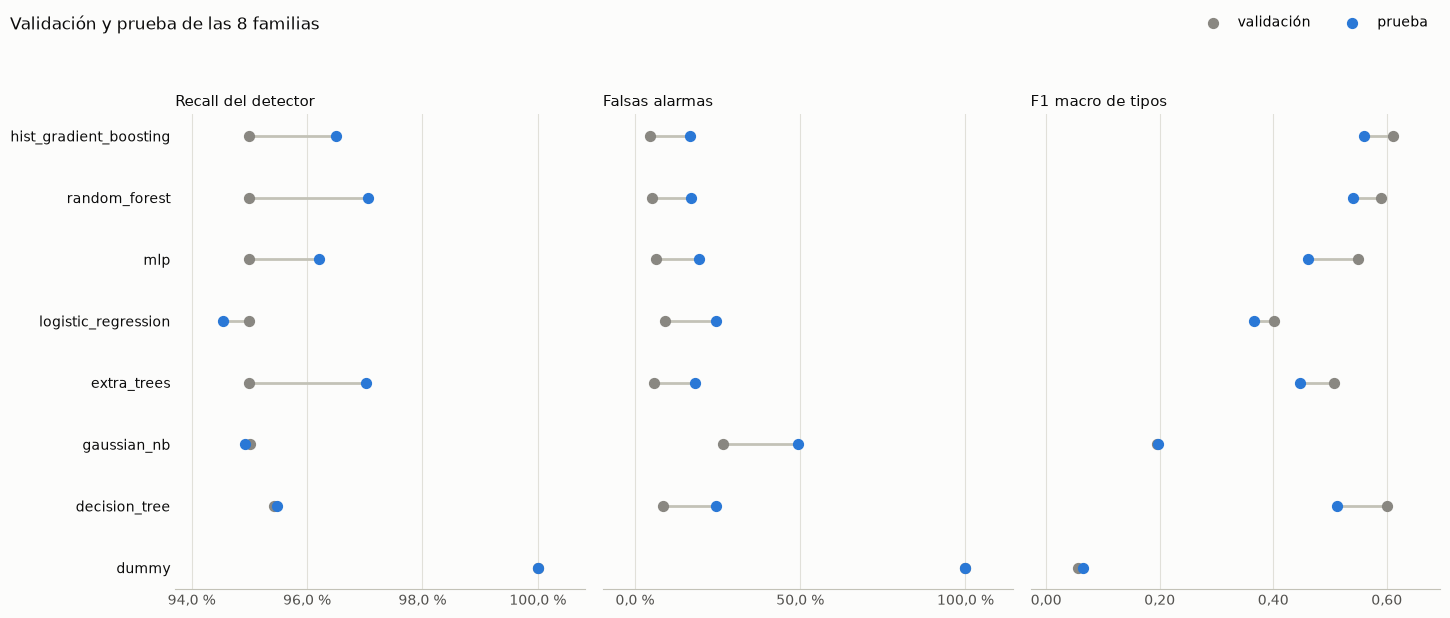

In [8]:
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
VALIDATION_COLOR, TEST_COLOR = "#898781", "#2a78d6"
percent = FuncFormatter(lambda value, _: f"{value * 100:.0f} %")
decimal = FuncFormatter(lambda value, _: f"{value:.2f}".replace(".", ","))
score = FuncFormatter(lambda value, _: f"{value:.3f}".replace(".", ","))
percent_1 = FuncFormatter(lambda value, _: f"{value * 100:.1f} %".replace(".", ","))


def dumbbells(rows, panels, left, right, labels, title, path):
    """Una figura con un panel por métrica; cada fila une el valor de left (gris) con el de right (azul)."""
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels) + 2, 0.55 * len(rows) + 1.8), sharey=True, facecolor=SURFACE)
    for ax, (metric, panel_title, formatter) in zip(axes, panels):
        ax.set_facecolor(SURFACE)
        for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
            a, b = row[left.format(metric)], row[right.format(metric)]
            ax.plot([a, b], [position, position], color=AXIS, linewidth=2, zorder=1)
            ax.scatter(a, position, s=50, color=VALIDATION_COLOR, zorder=2, label=labels[0] if position == 0 else None)
            ax.scatter(b, position, s=50, color=TEST_COLOR, zorder=3, label=labels[1] if position == 0 else None)
        ax.set_title(panel_title, loc="left", color=INK, fontsize=11)
        ax.xaxis.set_major_formatter(formatter)
        # Marcas en múltiplos de 1, 2 o 5: así cada etiqueta es el valor exacto de su posición.
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.margins(x=0.15)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    axes[0].set_yticks(range(len(rows)), list(reversed(rows.index)), color=INK)
    handles, names = axes[0].get_legend_handles_labels()
    fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.legend(handles, names, ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    fig.savefig(path, dpi=200, facecolor=SURFACE)
    plt.show()


families = results[results["kind"] != "m3"].set_index("name")
dumbbells(
    families,
    [("recall", "Recall del detector", percent_1), ("false_alarm_rate", "Falsas alarmas", percent_1), ("macro_f1", "F1 macro de tipos", decimal)],
    "validation_{}", "test_{}", ("validación", "prueba"),
    "Validación y prueba de las 8 familias", MODEL_SEARCH_DIR / "validation_vs_test.png",
)

### Figura: el experimento de TTL en prueba

Para los 3 modelos elegidos: su versión de la app (gris, con las variables de TTL) y su versión M3 (azul, sin ellas, con los mismos hiperparámetros), en prueba. Se guarda en `ttl_test.png`.

,pr_auc_app,pr_auc_m3,false_alarm_rate_app,false_alarm_rate_m3,macro_f1_app,macro_f1_m3,pr_auc_diferencia,false_alarm_rate_diferencia,macro_f1_diferencia
family,,,,,,,,,
hist_gradient_boosting,0.9883,0.9870,0.1653,0.1734,0.5596,0.5399,-0.0013,+0.0081,-0.0197
random_forest,0.9886,0.9883,0.1693,0.1687,0.5400,0.5369,-0.0003,-0.0006,-0.0031
mlp,0.9843,0.9813,0.1941,0.1951,0.4621,0.4008,-0.0030,+0.0009,-0.0613


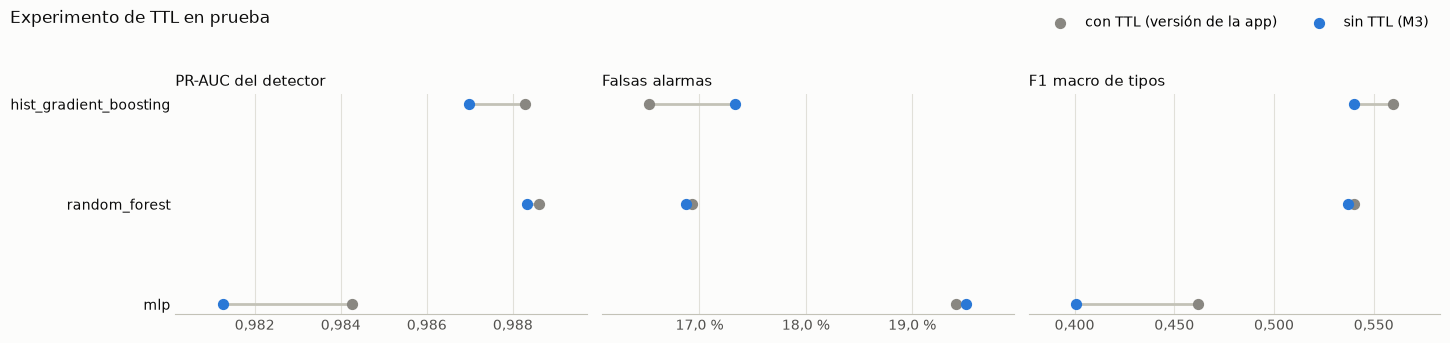

In [9]:
chosen = results[results["kind"] == "elegido"].set_index("family")
m3 = results[results["kind"] == "m3"].set_index("family")
ttl = pd.DataFrame(
    {
        f"{metric}_{version}": table.loc[chosen.index, f"test_{metric}"]
        for metric in ("pr_auc", "false_alarm_rate", "macro_f1")
        for version, table in (("app", chosen), ("m3", m3))
    }
)
display(
    ttl.assign(**{f"{metric}_diferencia": ttl[f"{metric}_m3"] - ttl[f"{metric}_app"] for metric in ("pr_auc", "false_alarm_rate", "macro_f1")})
    .style.format("{:+.4f}", subset=[f"{metric}_diferencia" for metric in ("pr_auc", "false_alarm_rate", "macro_f1")])
    .format("{:.4f}", subset=[c for c in ttl.columns])
)
dumbbells(
    ttl,
    [("pr_auc", "PR-AUC del detector", score), ("false_alarm_rate", "Falsas alarmas", percent_1), ("macro_f1", "F1 macro de tipos", score)],
    "{}_app", "{}_m3", ("con TTL (versión de la app)", "sin TTL (M3)"),
    "Experimento de TTL en prueba", MODEL_SEARCH_DIR / "ttl_test.png",
)

### Figura: F1 por tipo de ataque en prueba

El F1 de cada tipo de ataque en prueba para las 8 familias, en una escala de un solo color (más oscuro, más alto). Se guarda en `test_f1_per_type.png`.

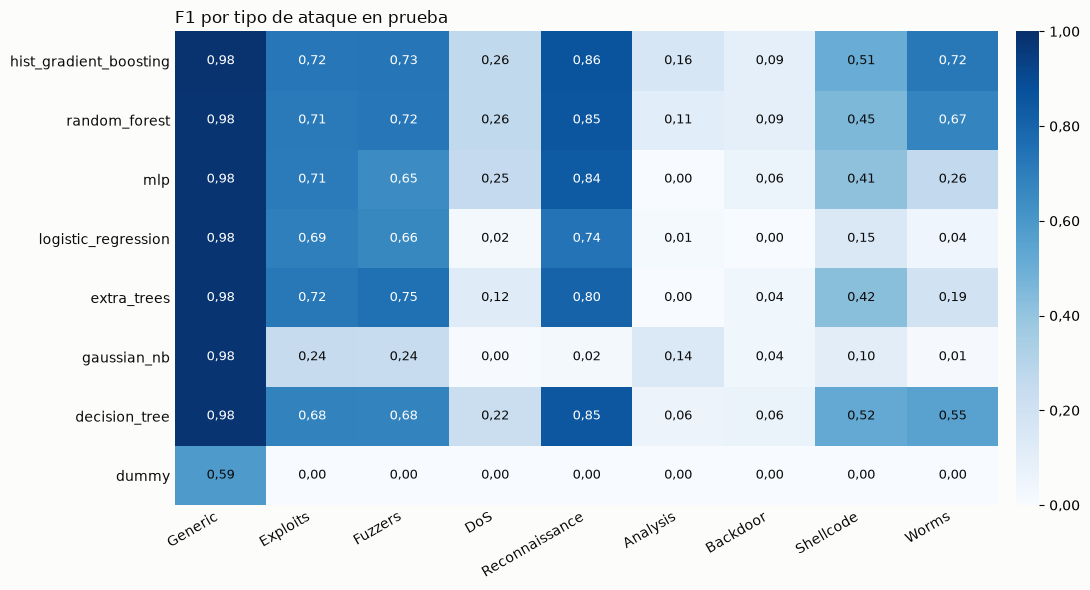

In [10]:
f1_table = test_types.pivot(index="name", columns="attack_cat", values="f1").reindex(index=families.index, columns=ATTACK_TYPES)
fig, ax = plt.subplots(figsize=(11, 0.55 * len(f1_table) + 1.6), facecolor=SURFACE)
image = ax.imshow(f1_table.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(f1_table.shape[0]):
    for j in range(f1_table.shape[1]):
        value = f1_table.iat[i, j]
        text = "—" if pd.isna(value) else f"{value:.2f}".replace(".", ",")
        ax.text(j, i, text, ha="center", va="center", fontsize=9, color="white" if not pd.isna(value) and value > 0.6 else INK)
ax.set_xticks(range(len(ATTACK_TYPES)), ATTACK_TYPES, rotation=30, ha="right", color=INK)
ax.set_yticks(range(len(f1_table)), f1_table.index, color=INK)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
colorbar.ax.yaxis.set_major_formatter(decimal)
colorbar.outline.set_visible(False)
ax.set_title("F1 por tipo de ataque en prueba", loc="left", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(MODEL_SEARCH_DIR / "test_f1_per_type.png", dpi=200, facecolor=SURFACE)
plt.show()

### Medición fuera de la bolsa del Random Forest

La PR-AUC del detector y el F1 macro del clasificador del Random Forest elegido, medidos fuera de la bolsa (con los flujos de entrenamiento que cada árbol no vio) y en la validación agrupada. Lo fuera de la bolsa no respeta los grupos de flujos idénticos: una copia exacta de un flujo puede estar en la bolsa de un árbol mientras el flujo se mide fuera de ella. Es un dato complementario: **con `class_weight="balanced"`, en este modelo no mide los tipos de ataque poco frecuentes (ver abajo), y por eso no reemplaza la validación agrupada.** Para el artículo vale solo el valor corregido que calcula esta celda. Para medirlo se vuelve a entrenar el Random Forest elegido con la parte de entrenamiento (`oob_score=True` no cambia los árboles); no se usa la prueba.

Dos comportamientos de scikit-learn 1.9.1, comprobados en su código, que cambian cómo se lee esta medición:

- **La bolsa no se sortea igual para todos los flujos.** Con `class_weight="balanced"`, cada árbol sortea su bolsa con una probabilidad proporcional al peso de clase de cada flujo. Los tipos con más peso (los menos frecuentes) entran en la bolsa de casi todos los árboles y quedan fuera de muy pocos o de ninguno.
- **Un flujo que no quedó fuera de ningún árbol no tiene medición**, pero su fila de `oob_decision_function_` queda en ceros, no vacía. Esta medición cuenta los árboles de cada flujo y deja fuera a esos flujos (`flows_without_oob`).

La celda de entrenamiento escribió `oob_vs_validation.csv` sin esa segunda corrección: contaba como medidos, con probabilidades en cero, a los flujos sin ningún árbol fuera de la bolsa. Esta celda lo vuelve a calcular con la corrección y lo reemplaza.

In [11]:
from threat_detector.config import MAX_MODEL_SIZE_MB, MODEL_SEARCH_CSV
from threat_detector.dataset import load_train
from threat_detector.ml.preprocessing import split_train_validation
from threat_detector.ml.training import apply_simplicity_rule, oob_comparison, oob_per_type, read_search_results, select_candidates

search = read_search_results(MODEL_SEARCH_CSV)
final_choice = apply_simplicity_rule(
    search, select_candidates(search, phases=[1, 2], max_size_mb=MAX_MODEL_SIZE_MB), max_size_mb=MAX_MODEL_SIZE_MB
)
oob_training_part = split_train_validation(load_train())[0]
oob = oob_comparison(search, final_choice, oob_training_part)
oob.to_csv(OOB_CSV, index=False)
display(oob.style.format({"oob": "{:.4f}", "grouped_validation": "{:.4f}", "difference": "{:+.4f}"}).hide(axis="index"))

family,task,metric,oob,grouped_validation,difference,train_flows,flows_without_oob
random_forest,detector,pr_auc,0.9964,0.9964,+0.0000,140273,0
random_forest,attack_type,macro_f1,0.4102,0.6031,-0.1929,95473,3921


Para ver de qué tipos sale la diferencia, la tabla siguiente da la precisión, el recall y el F1 de cada tipo fuera de la bolsa (`oob_*`, solo con los flujos medidos) y en la validación agrupada (`validation_*`, la fila de la búsqueda, sobre todos los ataques de validación), y se guarda en `oob_per_type.csv`. Por tipo también dice cuántos flujos de entrenamiento tiene, cuántos quedaron sin medición y en cuántos árboles quedó fuera de la bolsa cada flujo en promedio (`oob_trees_mean`).

Límite de la medición: el clasificador tiene 25 árboles. Si la bolsa se sorteara igual para todos los flujos, cada uno quedaría fuera de unos 9 (25 × e⁻¹ ≈ 9,2); con `class_weight="balanced"`, los tipos frecuentes quedan fuera de más árboles y los menos frecuentes de muy pocos o de ninguno. La predicción fuera de la bolsa de cada flujo promedia solo esos árboles, no los 25 del modelo, y en los tipos sin flujos medidos no hay medición.

In [12]:
oob_types = oob_per_type(search, final_choice, oob_training_part)
oob_types.to_csv(MODEL_SEARCH_DIR / "oob_per_type.csv", index=False)
shown = ["attack_cat", "train_flows", "flows_without_oob", "oob_trees_mean", "oob_precision", "validation_precision",
         "oob_recall", "validation_recall", "oob_f1", "validation_f1", "f1_difference"]
display(oob_types[shown].style.format(
    {**{c: "{:.3f}" for c in shown if c.startswith(("oob_p", "oob_r", "oob_f", "validation_", "f1_"))}, "oob_trees_mean": "{:.2f}"},
    na_rep="—",
).hide(axis="index"))

attack_cat,train_flows,flows_without_oob,oob_trees_mean,oob_precision,validation_precision,oob_recall,validation_recall,oob_f1,validation_f1,f1_difference
Generic,32000,0,17.96,0.999,0.999,0.979,0.979,0.989,0.989,-0.000
Exploits,26714,0,16.83,0.888,0.894,0.520,0.523,0.656,0.660,-0.004
Fuzzers,14548,0,12.04,0.952,0.943,0.893,0.891,0.922,0.916,0.005
DoS,9811,0,8.48,0.308,0.371,0.293,0.442,0.300,0.404,-0.103
Reconnaissance,8393,1,7.06,0.866,0.867,0.778,0.799,0.820,0.832,-0.012
Analysis,1600,1529,0.05,0.002,0.156,0.113,0.360,0.004,0.217,-0.213
Backdoor,1397,1381,0.01,0.000,0.075,0.125,0.547,0.000,0.132,-0.131
Shellcode,906,906,0.00,0.000,0.580,—,0.815,0.000,0.678,-0.678
Worms,104,104,0.00,0.000,0.529,—,0.692,0.000,0.600,-0.600


### Modelos registrados en la app

El registro (`artifacts/registry.json`) y el tamaño de cada `model.joblib`. El modelo simulado ya no está registrado; su carpeta queda en `artifacts/models/mock/` para las pruebas de la app.

In [13]:
registry = read_registry()
rows = []
for entry in registry["models"]:
    info = read_model_info(entry["name"])
    folder = MODELS_DIR / entry["name"]
    rows.append({
        "name": entry["name"],
        "display_name": info["display_name"],
        "por_defecto": entry["name"] == registry["default_model"],
        "método": info["preprocessing_method"],
        "explicación": info["explanation_method"] or "no explica",
        "model.joblib (MB)": (folder / MODEL_JOBLIB).stat().st_size / BYTES_PER_MB,
        "archivos": f"{folder.relative_to(ROOT)}/{MODEL_JOBLIB}, {MODEL_JSON}",
    })
registered = pd.DataFrame(rows)
display(registered.style.format({"model.joblib (MB)": "{:.1f}"}).hide(axis="index"))
print(f"Tamaño total de los model.joblib: {registered['model.joblib (MB)'].sum():.1f} MB")
print(f"Modelo simulado registrado: {'sí' if 'mock' in registered['name'].values else 'no'}")

name,display_name,por_defecto,método,explicación,model.joblib (MB),archivos
hist_gradient_boosting,HistGradientBoosting,True,m1,shap_tree,14.2,"artifacts/models/hist_gradient_boosting/model.joblib, model.json"
random_forest,Random Forest,False,m2,shap_tree,43.4,"artifacts/models/random_forest/model.joblib, model.json"
mlp,Red neuronal (MLP),False,m2,no explica,0.4,"artifacts/models/mlp/model.joblib, model.json"
logistic_regression,Regresión logística (modelo base),False,m2,linear_logit,0.0,"artifacts/models/logistic_regression/model.joblib, model.json"


Tamaño total de los model.joblib: 58.0 MB
Modelo simulado registrado: no


## 5. Falsas alarmas por categoría

En todos los modelos, la tasa de falsas alarmas sube de validación a prueba. Esta sección muestra qué flujos normales generan esas falsas alarmas, desglosados por `service`, `proto` y `state`, y los compara con los normales de entrenamiento y de validación.

- **Cómo se calcula.** Los 4 modelos registrados se cargan de `artifacts/models/` y predicen con `predict_flows` y el umbral de su `model.json`, como la app. Son las mismas predicciones de la evaluación: no se entrena nada, no se vuelve a evaluar ningún modelo y no se cambia `test_results.csv`. Como comprobación, las falsas alarmas por categoría deben sumar exactamente el `fp` guardado en `test_results.csv`. Los otros 7 modelos no se guardaron y no se analizan.
- **`in_training`** dice cómo ve cada categoría el preprocesador del detector: `propia` (tiene su propia columna), `agrupada` (está en el entrenamiento, pero es rara y va a la columna "infrecuente") o `nueva` (no aparece en el entrenamiento y también va a "infrecuente").
- **Pocos normales.** Una categoría con menos de 100 normales en prueba se marca con un marcador sin relleno: con 100 normales, el intervalo de confianza del 95 % de una tasa (aproximación normal) llega a ±9,8 puntos en el peor caso (tasa de 50 %), así que con menos su tasa no es concluyente.
- **Alcance.** El análisis solo desglosa por `service`, `proto` y `state`. Si estas categorías no explican la mayor parte de las falsas alarmas, se dice así, sin forzar una explicación.

In [14]:
from threat_detector.artifacts import load_model
from threat_detector.dataset import load_test, load_train
from threat_detector.ml.evaluation import false_alarms_by_category
from threat_detector.ml.preprocessing import split_train_validation

# Normales mínimos en prueba para leer la tasa de una categoría (ver el texto de arriba).
MIN_TEST_NORMALS = 100

training_part, validation_part = split_train_validation(load_train())
parts = {"train": training_part, "validation": validation_part, "test": load_test()}
saved = results.set_index("name")
tables = []
for entry in read_registry()["models"]:
    name = entry["name"]
    info = read_model_info(name)
    table = false_alarms_by_category(load_model(name, info), info, parts)
    # Comprobación: por cada variable, las falsas alarmas suman el fp guardado en la evaluación.
    for split in ("validation", "test"):
        totals = table.groupby("column")[f"{split}_false_alarms"].sum()
        assert (totals == saved.loc[name, f"{split}_fp"]).all(), f"{name}: no coincide con {split}_fp"
    tables.append(table.assign(model=name))
by_category = pd.concat(tables, ignore_index=True)
by_category = by_category[["model", *[c for c in by_category.columns if c != "model"]]]
by_category.to_csv(MODEL_SEARCH_DIR / "false_alarms_by_category.csv", index=False)
print("Comprobación: las falsas alarmas por categoría suman el fp de test_results.csv en los 4 modelos.")
print(f"Guardado: artifacts/{MODEL_SEARCH_DIR.name}/false_alarms_by_category.csv ({len(by_category)} filas)")

Comprobación: las falsas alarmas por categoría suman el fp de test_results.csv en los 4 modelos.
Guardado: artifacts/model_search/false_alarms_by_category.csv (108 filas)


Para cada modelo y variable: en cuántas categorías caen las falsas alarmas de prueba y cuánto suman las 2 primeras; las 5 categorías con más falsas alarmas; y qué parte de las falsas alarmas sale de categorías propias, agrupadas o nuevas. Los normales tienen pocas categorías en cada variable (7 en `proto` y 10 en `service` y en `state`, contando las tres partes).

In [15]:
top_columns = [
    "category", "in_training", "train_normals", "validation_normals", "test_normals",
    "train_false_alarm_rate", "validation_false_alarm_rate", "test_false_alarm_rate", "test_false_alarms",
    "share_of_test_false_alarms",
]
rate_format = {c: "{:.1%}" for c in ("train_false_alarm_rate", "validation_false_alarm_rate", "test_false_alarm_rate", "share_of_test_false_alarms")}
for name, model_rows in by_category.groupby("model", sort=False):
    for column, rows in model_rows.groupby("column"):
        top = rows.head(5)
        with_alarms = int((rows["test_false_alarms"] > 0).sum())
        print(f"{name} · {column}: las falsas alarmas de prueba están en {with_alarms} de sus {len(rows)} categorías; "
              f"las 2 con más suman {rows.head(2)['share_of_test_false_alarms'].sum():.1%}")
        display(top[top_columns].style.format(rate_format, na_rep="—").hide(axis="index"))
    status = model_rows.groupby(["column", "in_training"])["share_of_test_false_alarms"].sum().unstack(fill_value=0)
    print(f"{name}: parte de las falsas alarmas de prueba según cómo ve el modelo la categoría")
    display(status.style.format("{:.1%}"))

hist_gradient_boosting · proto: las falsas alarmas de prueba están en 3 de sus 7 categorías; las 2 con más suman 99.7%


category,in_training,train_normals,validation_normals,test_normals,train_false_alarm_rate,validation_false_alarm_rate,test_false_alarm_rate,test_false_alarms,share_of_test_false_alarms
tcp,propia,31281,7840,27848,1.5%,4.2%,13.8%,3844,62.9%
udp,propia,11149,2773,8097,3.5%,6.5%,27.8%,2252,36.8%
igmp,agrupada,13,5,30,23.1%,60.0%,66.7%,20,0.3%
arp,propia,2292,567,987,0.0%,0.0%,0.0%,0,0.0%
icmp,agrupada,12,3,0,0.0%,0.0%,—,0,0.0%


hist_gradient_boosting · service: las falsas alarmas de prueba están en 5 de sus 10 categorías; las 2 con más suman 97.5%


category,in_training,train_normals,validation_normals,test_normals,train_false_alarm_rate,validation_false_alarm_rate,test_false_alarm_rate,test_false_alarms,share_of_test_false_alarms
-,propia,29225,7287,27375,2.6%,5.7%,18.6%,5079,83.0%
http,propia,4276,1072,4013,2.0%,7.4%,22.1%,886,14.5%
ftp,propia,992,226,758,0.6%,7.1%,19.5%,148,2.4%
radius,agrupada,2,0,2,100.0%,—,100.0%,2,0.0%
dns,propia,6005,1488,3068,0.0%,0.0%,0.0%,1,0.0%


hist_gradient_boosting · state: las falsas alarmas de prueba están en 5 de sus 10 categorías; las 2 con más suman 99.7%


category,in_training,train_normals,validation_normals,test_normals,train_false_alarm_rate,validation_false_alarm_rate,test_false_alarm_rate,test_false_alarms,share_of_test_false_alarms
FIN,propia,29696,7479,24172,1.5%,4.4%,15.9%,3839,62.8%
INT,propia,4568,1147,4485,8.6%,15.9%,50.3%,2257,36.9%
REQ,propia,746,179,1707,0.0%,1.1%,0.9%,15,0.2%
CON,propia,9723,2376,6633,0.0%,0.0%,0.1%,4,0.1%
RST,agrupada,55,16,1,0.0%,6.2%,100.0%,1,0.0%


... (22 outputs left out)

logistic_regression · state: las falsas alarmas de prueba están en 4 de sus 10 categorías; las 2 con más suman 99.8%


category,in_training,train_normals,validation_normals,test_normals,train_false_alarm_rate,validation_false_alarm_rate,test_false_alarm_rate,test_false_alarms,share_of_test_false_alarms
FIN,propia,29696,7479,24172,10.3%,9.8%,28.1%,6788,74.4%
INT,propia,4568,1147,4485,21.9%,23.1%,51.5%,2311,25.3%
REQ,propia,746,179,1707,0.9%,1.1%,0.9%,15,0.2%
CON,propia,9723,2376,6633,0.1%,0.0%,0.1%,6,0.1%
ACC,nueva,0,0,2,—,—,0.0%,0,0.0%


logistic_regression: parte de las falsas alarmas de prueba según cómo ve el modelo la categoría


in_training,agrupada,nueva,propia
column,,,
proto,0.3%,0.0%,99.7%
service,0.0%,0.0%,100.0%
state,0.0%,0.0%,100.0%


### Figuras de HistGradientBoosting, el modelo por defecto

Para cada variable, las 8 categorías con más falsas alarmas en prueba. Junto a cada una: cómo la ve el modelo y cuántos normales tiene en entrenamiento / validación / prueba. Un marcador sin relleno indica menos de 100 normales en prueba.

- `false_alarms_by_category.png`: la tasa de falsas alarmas de cada categoría en entrenamiento, validación y prueba.
- `normal_mix_by_category.png`: la parte de los normales de cada parte que tiene esa categoría, para ver si la mezcla de normales cambió.

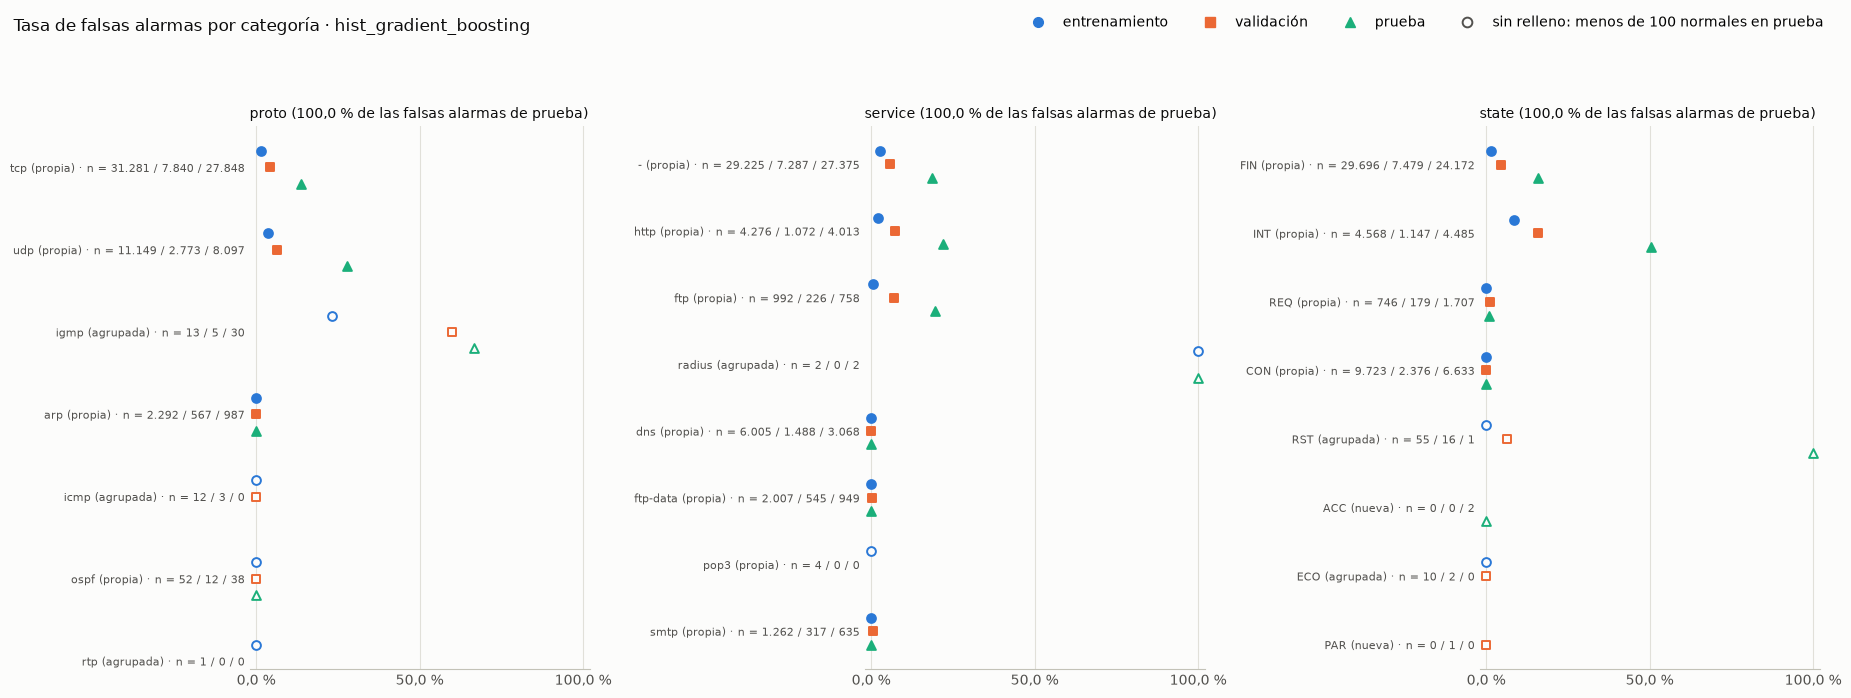

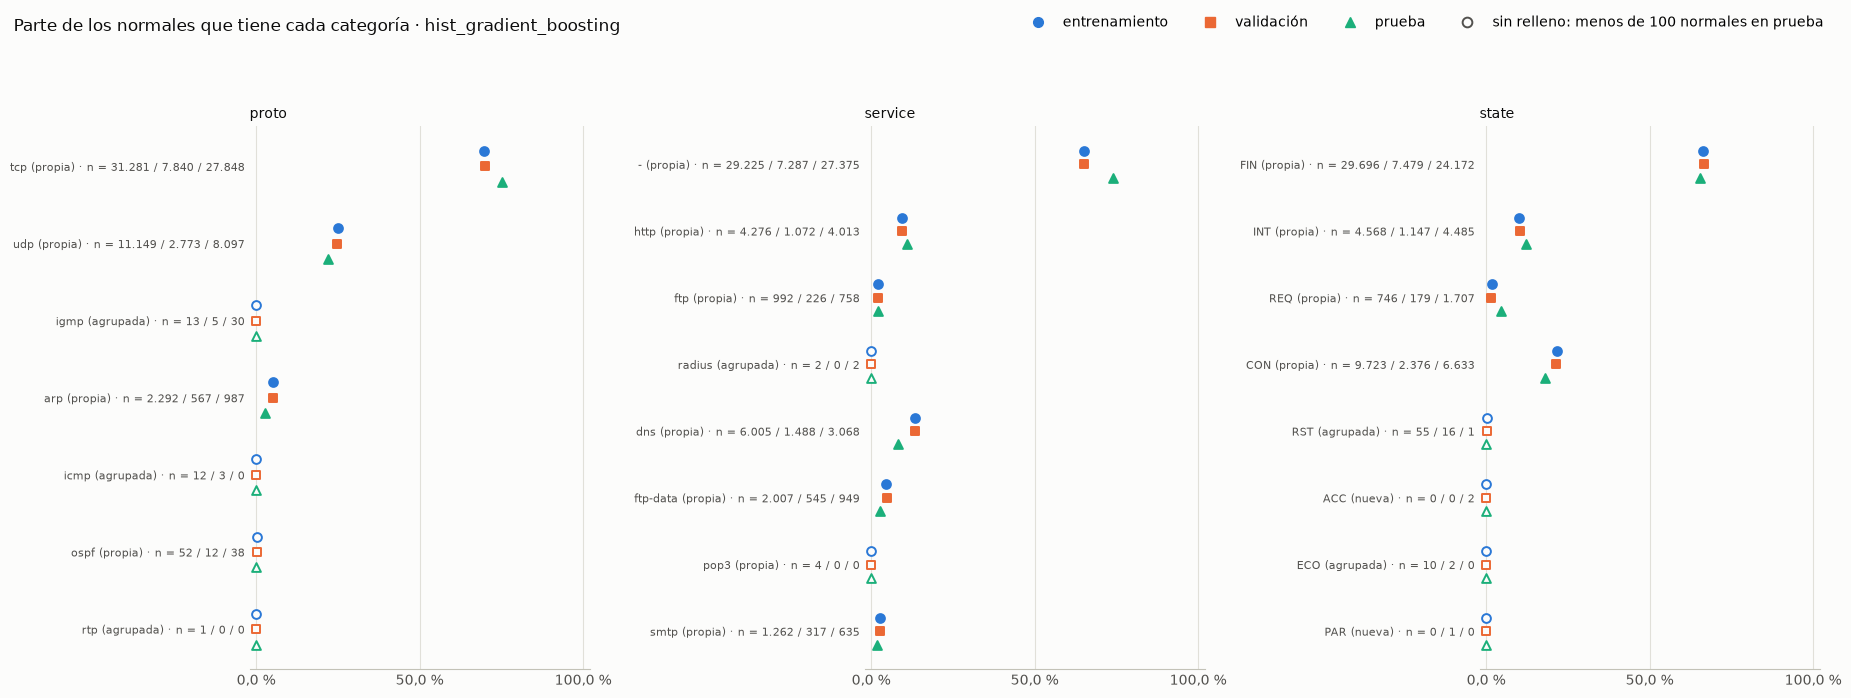

In [16]:
SPLITS = {"train": ("entrenamiento", "#2a78d6", "o"), "validation": ("validación", "#eb6834", "s"), "test": ("prueba", "#1baf7a", "^")}
TOP_CATEGORIES = 8
thousands = lambda n: f"{int(n):,}".replace(",", ".")


def category_figure(model_name, metric, panel_title, path, show_share=True):
    """Un panel por variable: el valor de metric en las tres partes, para las categorías con más falsas alarmas."""
    model_rows = by_category[by_category["model"] == model_name]
    columns = sorted(model_rows["column"].unique())
    fig, axes = plt.subplots(1, len(columns), figsize=(6.2 * len(columns), 0.6 * TOP_CATEGORIES + 2.2), facecolor=SURFACE)
    for ax, column in zip(axes, columns):
        rows = model_rows[model_rows["column"] == column].head(TOP_CATEGORIES)
        ax.set_facecolor(SURFACE)
        for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
            few = row["test_normals"] < MIN_TEST_NORMALS
            for offset, (split, (label, color, marker)) in zip((0.2, 0, -0.2), SPLITS.items()):
                value = row[f"{split}_{metric}"]
                if pd.isna(value):
                    continue
                ax.scatter(value, position + offset, s=40, marker=marker, color=color,
                           facecolor=SURFACE if few else color, linewidth=1.4, zorder=3,
                           label=label if position == 0 else None)
        labels = [
            f"{row['category']} ({row['in_training']}) · n = {thousands(row['train_normals'])} / "
            f"{thousands(row['validation_normals'])} / {thousands(row['test_normals'])}"
            for _, row in reversed(list(rows.iterrows()))
        ]
        ax.set_yticks(range(len(rows)), labels, color=INK, fontsize=8)
        share = f"{rows['share_of_test_false_alarms'].sum() * 100:.1f} %".replace(".", ",")
        title = f"{column} ({share} de las falsas alarmas de prueba)" if show_share else column
        ax.set_title(title, loc="left", color=INK, fontsize=10)
        ax.xaxis.set_major_formatter(percent_1)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
        ax.set_xlim(-0.02, 1.02)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
    # La leyenda se arma a mano: así muestra las tres partes con su marcador lleno, aunque la última
    # categoría del panel no tenga puntos en todas.
    handles = [plt.Line2D([], [], marker=marker, linestyle="", markersize=7, color=color) for _, color, marker in SPLITS.values()]
    names = [label for label, _, _ in SPLITS.values()]
    hollow = plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=MUTED, markerfacecolor=SURFACE, markeredgewidth=1.4)
    fig.suptitle(f"{panel_title} · {model_name}", x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.legend([*handles, hollow], [*names, f"sin relleno: menos de {MIN_TEST_NORMALS} normales en prueba"],
               ncol=4, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
    fig.savefig(path, dpi=200, facecolor=SURFACE)
    plt.show()


category_figure("hist_gradient_boosting", "false_alarm_rate", "Tasa de falsas alarmas por categoría",
                MODEL_SEARCH_DIR / "false_alarms_by_category.png")
category_figure("hist_gradient_boosting", "share", "Parte de los normales que tiene cada categoría",
                MODEL_SEARCH_DIR / "normal_mix_by_category.png", show_share=False)

### Qué muestra el desglose

Con las tres variables y en los 4 modelos:

- **Las falsas alarmas de prueba salen de las categorías más comunes de los normales, todas propias.** En HistGradientBoosting (6.116 falsas alarmas): `tcp` da el 62,9 % y `udp` el 36,8 %; en `service`, `-` da el 83,0 % y `http` el 14,5 %; en `state`, `FIN` da el 62,8 % y `INT` el 36,9 %. En los otros 3 modelos son las mismas categorías, con proporciones parecidas.
- **Las categorías agrupadas o nuevas casi no aportan:** como máximo el 0,5 % de las falsas alarmas de prueba en cualquier modelo y variable.
- **La tasa sube dentro de esas mismas categorías.** En HistGradientBoosting, de validación a prueba: `tcp` de 4,2 % a 13,8 %, `udp` de 6,5 % a 27,8 %, `-` de 5,7 % a 18,6 % e `INT` de 15,9 % a 50,3 %.
- **La mezcla de normales cambia poco.** La parte de `tcp` pasa de 70,0 % en validación a 75,3 % en prueba, la de `-` de 65,1 % a 74,0 % y la de `INT` de 10,2 % a 12,1 %; entre entrenamiento y validación es casi igual.

Alcance: con `service`, `proto` y `state` el aumento no se explica por categorías raras o nuevas ni por un cambio grande en la mezcla de normales, porque ocurre dentro de las categorías frecuentes. Este desglose no dice qué otras características de esos flujos normales lo producen.

## 6. Variables numéricas de los normales

Un análisis descriptivo de las variables numéricas de los flujos normales, con HistGradientBoosting (el modelo por defecto), dentro de los dos grupos que concentran sus falsas alarmas de prueba: **`tcp` + `FIN`** y **`udp` + `INT`**. Igual que en la sección 5: el modelo se carga de `artifacts/models/` y predice con su umbral, no se entrena nada y no se cambia `test_results.csv`. No se sacan conclusiones sobre los modelos.

En cada grupo, solo con flujos normales:

- **R, referencia:** entrenamiento contra validación. Cuánto difieren dos muestras del mismo archivo.
- **A:** entrenamiento contra prueba. Si los normales de prueba son distintos de los de entrenamiento.
- **B:** en prueba, los que dieron falsa alarma contra los que no.

**Medida:** la distancia de Kolmogorov–Smirnov (D), la diferencia máxima entre las dos distribuciones acumuladas, de 0 (iguales) a 1 (sin solapamiento). No depende de la escala ni la desvían los valores extremos. No se dan valores p: con miles de flujos casi cualquier diferencia sale "significativa"; la magnitud se lee contra la referencia R. Junto a D van la mediana y los cuartiles de cada lado, en la escala original. Se usan las 32 variables numéricas del modelo, incluidas `sttl`, `dttl` y `ct_state_ttl`; las tablas y figuras muestran las 10 con mayor D. Una comparación con menos de 100 flujos en algún lado se marca.

In [17]:
import numpy as np

from threat_detector.artifacts import predict_flows
from threat_detector.ml.evaluation import numeric_differences

NUMERIC_GROUPS = {"tcp + FIN": ("tcp", "FIN"), "udp + INT": ("udp", "INT")}
MIN_FLOWS = 100
TOP_VARIABLES = 10

hgb_info = read_model_info("hist_gradient_boosting")
hgb = load_model("hist_gradient_boosting", hgb_info)
numeric_cols = hgb_info["numeric_cols"]
normals, alerted = {}, {}
for split, flows in parts.items():
    _, alerts, _ = predict_flows(hgb, hgb_info, flows)
    is_normal = (flows["label"] == 0).to_numpy()
    normals[split], alerted[split] = flows[is_normal], alerts[is_normal]

total_false_alarms = int(alerted["test"].sum())
comparisons = []
for group, (proto, state) in NUMERIC_GROUPS.items():
    in_group = {split: ((f["proto"] == proto) & (f["state"] == state)).to_numpy() for split, f in normals.items()}
    group_alarms = int((alerted["test"] & in_group["test"]).sum())
    print(f"{group}: {group_alarms} de las {total_false_alarms} falsas alarmas de prueba ({group_alarms / total_false_alarms:.1%})")
    test_group = normals["test"][in_group["test"]]
    test_alerts = alerted["test"][in_group["test"]]
    pairs = {
        "R": (normals["train"][in_group["train"]], normals["validation"][in_group["validation"]]),
        "A": (normals["train"][in_group["train"]], test_group),
        "B": (test_group[test_alerts], test_group[~test_alerts]),
    }
    for comparison, (first, second) in pairs.items():
        table = numeric_differences(first, second, numeric_cols)
        comparisons.append(table.assign(group=group, comparison=comparison, few_flows=min(len(first), len(second)) < MIN_FLOWS))
numeric_table = pd.concat(comparisons, ignore_index=True)
numeric_table = numeric_table[["group", "comparison", *[c for c in numeric_table.columns if c not in ("group", "comparison")]]]
numeric_table.to_csv(MODEL_SEARCH_DIR / "numeric_differences_normals.csv", index=False)
print(f"Guardado: artifacts/{MODEL_SEARCH_DIR.name}/numeric_differences_normals.csv ({len(numeric_table)} filas)")
print(numeric_table.groupby(["group", "comparison"])[["first_flows", "second_flows", "few_flows"]].first())

tcp + FIN: 3839 de las 6116 falsas alarmas de prueba (62.8%)
udp + INT: 2237 de las 6116 falsas alarmas de prueba (36.6%)
Guardado: artifacts/model_search/numeric_differences_normals.csv (192 filas)
                      first_flows  second_flows  few_flows
group     comparison                                      
tcp + FIN A                 29696         24172      False
          B                  3839         20333      False
          R                 29696          7479      False
udp + INT A                  2332          3528      False
          B                  2237          1291      False
          R                  2332           591      False


Para cada grupo, las 10 variables con mayor D en A y en B, con la D de la referencia R para la misma variable. En A, `first` son los normales de entrenamiento y `second` los de prueba; en B, `first` son los normales de prueba que dieron falsa alarma y `second` los que no.

In [18]:
reference = numeric_table[numeric_table["comparison"] == "R"].set_index(["group", "variable"])["ks_d"]
shown = ["variable", "ks_d", "R_ks_d", "first_median", "second_median", "first_q25", "first_q75", "second_q25", "second_q75"]
for group in NUMERIC_GROUPS:
    for comparison in ("A", "B"):
        rows = numeric_table[(numeric_table["group"] == group) & (numeric_table["comparison"] == comparison)]
        rows = rows.assign(R_ks_d=[reference[(group, v)] for v in rows["variable"]]).nlargest(TOP_VARIABLES, "ks_d")
        print(f"{group} · {comparison}")
        display(rows[shown].style.format({"ks_d": "{:.3f}", "R_ks_d": "{:.3f}"}, precision=2).hide(axis="index"))

tcp + FIN · A


variable,ks_d,R_ks_d,first_median,second_median,first_q25,first_q75,second_q25,second_q75
ackdat,0.318,0.010,0.00,0.00,0.00,0.00,0.00,0.07
dttl,0.265,0.008,29.00,31.00,29.00,29.00,29.00,252.00
sttl,0.264,0.008,31.00,31.00,31.00,31.00,31.00,254.00
ct_state_ttl,0.264,0.008,0.00,0.00,0.00,0.00,0.00,1.00
dbytes,0.262,0.014,3380.00,1268.00,1128.00,23508.00,354.00,10168.00
synack,0.260,0.010,0.00,0.01,0.00,0.00,0.00,0.08
dload,0.243,0.014,284986.06,15048.95,11144.92,3882855.12,3531.20,1111473.62
dloss,0.230,0.007,6.00,3.00,2.00,18.00,1.00,8.00
dpkts,0.223,0.008,18.00,12.00,10.00,52.00,8.00,38.00
dinpkt,0.222,0.013,6.63,59.61,0.65,64.08,1.16,105.75


tcp + FIN · B


variable,ks_d,R_ks_d,first_median,second_median,first_q25,first_q75,second_q25,second_q75
sttl,0.595,0.008,254.00,31.00,254.00,254.00,31.00,254.00
dttl,0.595,0.008,252.00,29.00,252.00,252.00,29.00,252.00
ct_state_ttl,0.595,0.008,1.00,0.00,1.00,1.00,0.00,1.00
ackdat,0.595,0.010,0.07,0.00,0.06,0.09,0.00,0.06
synack,0.595,0.010,0.08,0.00,0.06,0.10,0.00,0.08
dload,0.561,0.014,3632.53,66176.29,2336.24,5897.77,4160.66,2252011.25
dbytes,0.546,0.014,612.00,1644.00,354.00,844.00,354.00,14682.00
dinpkt,0.506,0.013,121.38,29.66,82.95,181.10,0.99,90.39
dloss,0.497,0.007,1.00,4.00,1.00,2.00,1.00,12.00
dpkts,0.481,0.008,8.00,18.00,8.00,10.00,8.00,42.00


udp + INT · A


variable,ks_d,R_ks_d,first_median,second_median,first_q25,first_q75,second_q25,second_q75
ct_srv_dst,0.226,0.060,10.00,5.00,4.00,25.00,3.00,12.00
ct_dst_src_ltm,0.217,0.059,8.00,4.00,4.00,25.00,2.00,12.00
ct_srv_src,0.182,0.068,9.00,6.00,5.00,25.00,3.00,14.00
ct_dst_ltm,0.159,0.037,3.00,2.00,2.00,8.00,1.00,5.00
sbytes,0.109,0.026,503.00,198.00,104.00,1064.00,104.00,1064.00
smean,0.106,0.023,252.00,98.00,52.00,532.00,52.00,532.00
ct_src_dport_ltm,0.103,0.037,2.00,2.00,1.00,8.00,1.00,5.00
ct_src_ltm,0.102,0.044,3.00,3.00,2.00,9.00,1.00,7.00
sinpkt,0.079,0.049,0.01,0.01,0.00,0.01,0.00,0.01
dur,0.078,0.047,0.00,0.00,0.00,0.00,0.00,0.00


udp + INT · B


variable,ks_d,R_ks_d,first_median,second_median,first_q25,first_q75,second_q25,second_q75
ct_srv_dst,0.387,0.060,4.00,8.00,2.00,8.00,5.00,23.00
ct_srv_src,0.349,0.068,4.00,8.00,3.00,11.00,5.00,23.00
ct_dst_src_ltm,0.341,0.059,3.00,7.00,2.00,7.00,4.00,23.00
smean,0.201,0.023,101.00,73.00,52.00,532.00,39.00,532.00
sbytes,0.199,0.026,206.00,178.00,104.00,1064.00,78.00,1064.00
ct_src_dport_ltm,0.197,0.037,2.00,2.00,1.00,4.00,1.00,6.00
ct_dst_ltm,0.168,0.037,2.00,3.00,1.00,3.00,2.00,6.00
sload,0.125,0.053,190400000.00,309333312.00,69333328.00,474400000.00,52000000.00,472888864.00
ct_src_ltm,0.100,0.044,2.00,3.00,1.00,6.00,2.00,7.00
rate,0.039,0.046,125000.00,125000.00,111111.11,250000.00,100000.00,250000.00


`numeric_differences_normals.png`: por grupo, la D de las 10 variables con mayor diferencia en A (izquierda) y en B (derecha), con la referencia R de la misma variable en gris.

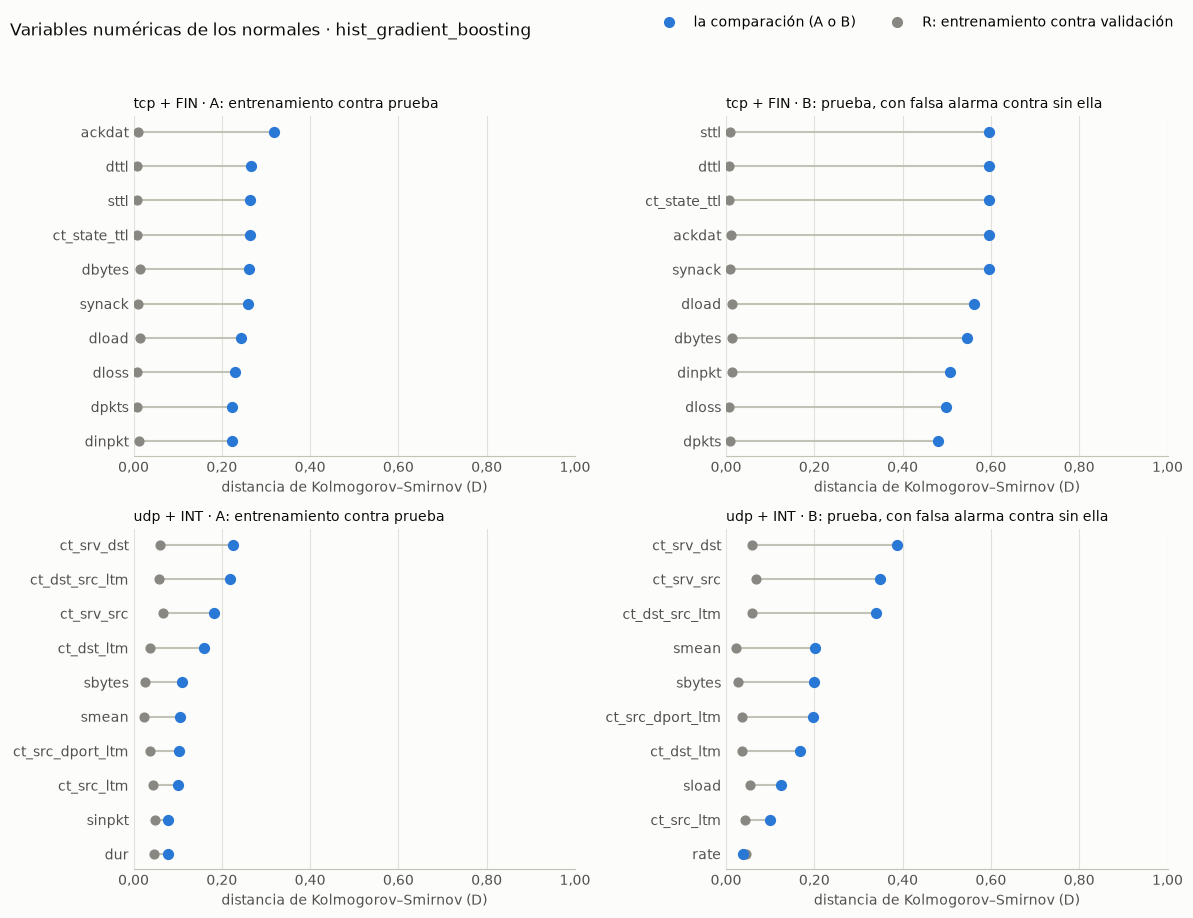

In [19]:
COMPARISON_COLOR, REFERENCE_COLOR = "#2a78d6", "#898781"
titles = {"A": "A: entrenamiento contra prueba", "B": "B: prueba, con falsa alarma contra sin ella"}
fig, axes = plt.subplots(len(NUMERIC_GROUPS), 2, figsize=(12, 4.6 * len(NUMERIC_GROUPS)), facecolor=SURFACE)
for row_axes, group in zip(axes, NUMERIC_GROUPS):
    for ax, comparison in zip(row_axes, ("A", "B")):
        rows = numeric_table[(numeric_table["group"] == group) & (numeric_table["comparison"] == comparison)].nlargest(TOP_VARIABLES, "ks_d")
        ax.set_facecolor(SURFACE)
        for position, (_, row) in enumerate(reversed(list(rows.iterrows()))):
            r = reference[(group, row["variable"])]
            ax.plot([r, row["ks_d"]], [position, position], color=AXIS, linewidth=1.5, zorder=1)
            ax.scatter(r, position, s=40, color=REFERENCE_COLOR, zorder=2, label="R: entrenamiento contra validación" if position == 0 else None)
            ax.scatter(row["ks_d"], position, s=50, color=COMPARISON_COLOR, zorder=3, label="la comparación" if position == 0 else None)
        ax.set_yticks(range(len(rows)), list(rows["variable"])[::-1], color=INK)
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(decimal)
        ax.set_xlabel("distancia de Kolmogorov–Smirnov (D)", color=MUTED)
        ax.set_title(f"{group} · {titles[comparison]}", loc="left", color=INK, fontsize=10)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=c) for c in (COMPARISON_COLOR, REFERENCE_COLOR)]
fig.suptitle("Variables numéricas de los normales · hist_gradient_boosting", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(handles, ["la comparación (A o B)", "R: entrenamiento contra validación"], ncol=2, frameon=False, loc="upper right", bbox_to_anchor=(0.99, 1.0))
fig.savefig(MODEL_SEARCH_DIR / "numeric_differences_normals.png", dpi=200, facecolor=SURFACE)
plt.show()

`numeric_ecdf_top.png`: para las 3 variables con mayor D en B en cada grupo, la distribución acumulada de los normales de prueba que dieron falsa alarma, los que no, y los de entrenamiento. En las variables con más de 20 valores distintos, el eje horizontal es lineal entre 0 y 1 y logarítmico desde ahí (escala `symlog`), para ver los valores en cero junto a los grandes; en las de pocos valores, como las de TTL, es lineal.

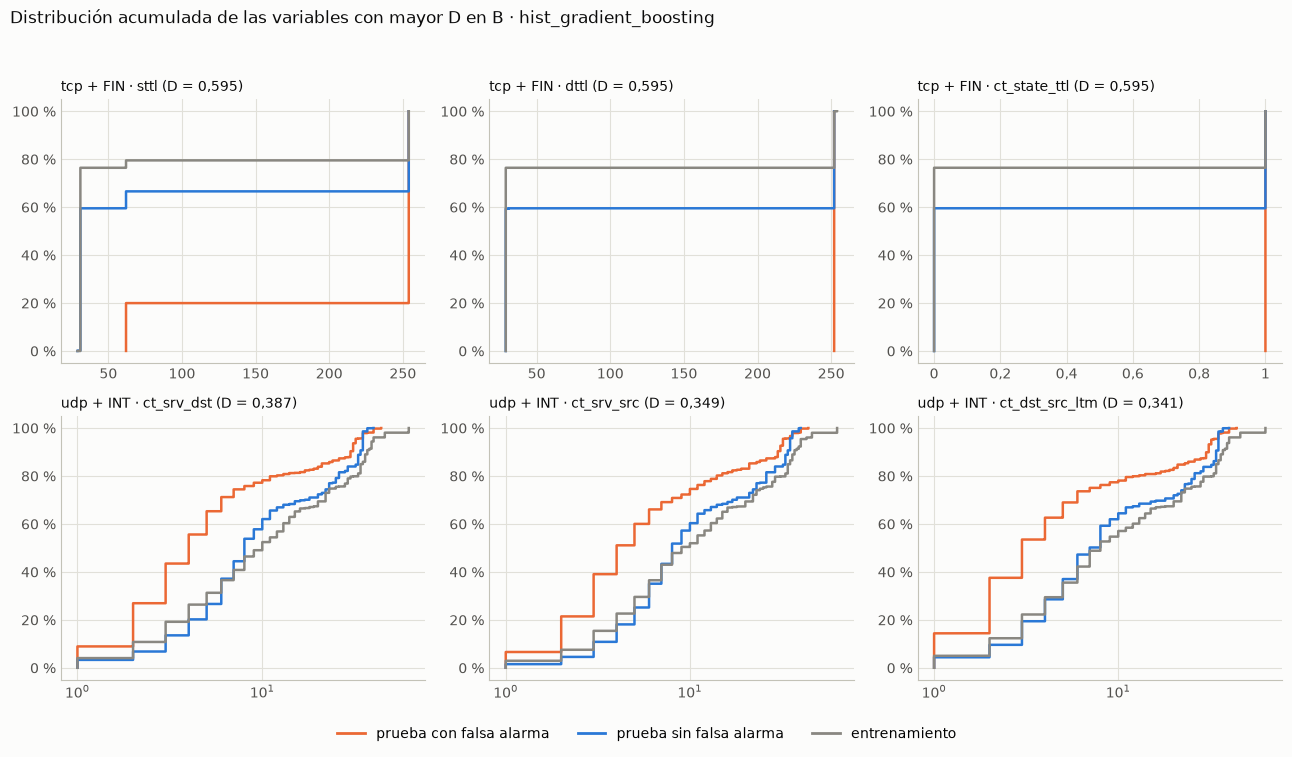

In [20]:
LINEAR_MAX_VALUES = 20
ECDF_LINES = {"prueba con falsa alarma": "#eb6834", "prueba sin falsa alarma": "#2a78d6", "entrenamiento": "#898781"}
fig, axes = plt.subplots(len(NUMERIC_GROUPS), 3, figsize=(13, 3.8 * len(NUMERIC_GROUPS)), facecolor=SURFACE)
for row_axes, (group, (proto, state)) in zip(axes, NUMERIC_GROUPS.items()):
    top = numeric_table[(numeric_table["group"] == group) & (numeric_table["comparison"] == "B")].nlargest(3, "ks_d")
    test_group = normals["test"][((normals["test"]["proto"] == proto) & (normals["test"]["state"] == state)).to_numpy()]
    test_alerts = alerted["test"][((normals["test"]["proto"] == proto) & (normals["test"]["state"] == state)).to_numpy()]
    train_group = normals["train"][((normals["train"]["proto"] == proto) & (normals["train"]["state"] == state)).to_numpy()]
    samples = {"prueba con falsa alarma": test_group[test_alerts], "prueba sin falsa alarma": test_group[~test_alerts], "entrenamiento": train_group}
    for ax, (_, row) in zip(row_axes, top.iterrows()):
        ax.set_facecolor(SURFACE)
        for label, flows in samples.items():
            values = np.sort(flows[row["variable"]].to_numpy(dtype=float))
            ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=ECDF_LINES[label], linewidth=1.8, label=label)
        # Escala symlog para las variables con muchos valores; lineal para las de pocos (como el TTL).
        if test_group[row["variable"]].nunique() > LINEAR_MAX_VALUES:
            ax.set_xscale("symlog", linthresh=1)
        else:
            ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}".replace(".", ",")))
        ax.yaxis.set_major_formatter(percent)
        ax.set_title(f"{group} · {row['variable']} (D = {row['ks_d']:.3f})".replace(".", ","), loc="left", color=INK, fontsize=10)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.spines["left"].set_color(AXIS)
        ax.tick_params(colors=MUTED, length=0)
handles = [plt.Line2D([], [], color=c, linewidth=2) for c in ECDF_LINES.values()]
fig.suptitle("Distribución acumulada de las variables con mayor D en B · hist_gradient_boosting", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
fig.legend(handles, list(ECDF_LINES), ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 0.0))
fig.savefig(MODEL_SEARCH_DIR / "numeric_ecdf_top.png", dpi=200, facecolor=SURFACE)
plt.show()

### Qué muestra la comparación

Solo describe las distribuciones; no dice por qué un modelo da alerta.

- **Los dos grupos concentran las falsas alarmas de prueba de HistGradientBoosting:** `tcp` + `FIN` tiene 3.839 de las 6.116 (62,8 %) y `udp` + `INT`, 2.237 (36,6 %).
- **Referencia R:** entre entrenamiento y validación, D no pasa de 0,018 en `tcp` + `FIN` ni de 0,068 en `udp` + `INT`.
- **`tcp` + `FIN`, A (entrenamiento contra prueba):** las mayores diferencias están en `ackdat` (D = 0,318), `dttl`, `sttl` y `ct_state_ttl` (0,264–0,265), `dbytes` (0,262) y `synack` (0,260), entre 18 y 35 veces la referencia.
- **`tcp` + `FIN`, B (con falsa alarma contra sin ella):** `sttl`, `dttl`, `ct_state_ttl`, `ackdat` y `synack` tienen D = 0,595, seguidas de `dload` (0,561) y `dbytes` (0,546). Los normales que dieron falsa alarma tienen medianas de `sttl` 254 y `dttl` 252, contra 31 y 29 de los que no.
- **`udp` + `INT`, A:** las mayores diferencias están en los contadores `ct_srv_dst` (0,226), `ct_dst_src_ltm` (0,217) y `ct_srv_src` (0,182), entre 2,7 y 3,8 veces la referencia.
- **`udp` + `INT`, B:** los mismos contadores tienen las mayores D (0,341–0,387); los normales que dieron falsa alarma tienen medianas más bajas en ellos (4 contra 8 en `ct_srv_dst`) y más altas en `smean` (101 contra 73).

### Comprobación: `sttl` = 254 y `dttl` = 252 en `tcp` + `FIN`

Una comprobación descriptiva de los valores que separan a los normales con y sin falsa alarma en `tcp` + `FIN`. Para cada parte (entrenamiento, validación y prueba), con todos los flujos del grupo: cuántos tienen `sttl` = 254 y qué proporción de ellos son ataques; lo mismo para `dttl` = 252. Entre los normales del grupo, qué proporción tiene `sttl` = 254. En prueba, qué parte de las falsas alarmas del grupo tiene `sttl` = 254. Usa las predicciones de HistGradientBoosting de la celda anterior; se guarda en `ttl_254_check.csv`.

In [21]:
ttl_rows = []
for split, flows in parts.items():
    group = flows[(flows["proto"] == "tcp") & (flows["state"] == "FIN")]
    group_normals = group[group["label"] == 0]
    row = {"split": split, "group_flows": len(group)}
    for column, value in (("sttl", 254), ("dttl", 252)):
        selected = group[group[column] == value]
        row[f"{column}_{value}_flows"] = len(selected)
        row[f"{column}_{value}_attack_share"] = selected["label"].mean() if len(selected) else None
    row["group_normals"] = len(group_normals)
    row["normals_sttl_254_share"] = (group_normals["sttl"] == 254).mean()
    if split == "test":
        in_group = ((normals["test"]["proto"] == "tcp") & (normals["test"]["state"] == "FIN")).to_numpy()
        group_alarms = normals["test"][in_group & alerted["test"]]
        row["false_alarms"] = len(group_alarms)
        row["false_alarms_sttl_254_share"] = (group_alarms["sttl"] == 254).mean()
    ttl_rows.append(row)
ttl_check = pd.DataFrame(ttl_rows)
ttl_check.to_csv(MODEL_SEARCH_DIR / "ttl_254_check.csv", index=False)
print(f"Guardado: artifacts/{MODEL_SEARCH_DIR.name}/ttl_254_check.csv")
share_columns = [c for c in ttl_check.columns if c.endswith("_share")]
display(ttl_check.style.format({**{c: "{:.1%}" for c in share_columns}, "false_alarms": "{:.0f}"}, na_rep="—").hide(axis="index"))

Guardado: artifacts/model_search/ttl_254_check.csv


split,group_flows,sttl_254_flows,sttl_254_attack_share,dttl_252_flows,dttl_252_attack_share,group_normals,normals_sttl_254_share,false_alarms,false_alarms_sttl_254_share
train,62224,26467,77.0%,39527,82.3%,29696,20.5%,—,—
validation,15601,6542,77.5%,9828,82.6%,7479,19.7%,—,—
test,39339,18908,47.8%,27227,55.7%,24172,40.8%,3839,80.0%


Lo que dice la tabla, en `tcp` + `FIN`:

- **Entrenamiento y validación:** de los flujos con `sttl` = 254, el 77,0 % y el 77,5 % son ataques; de los que tienen `dttl` = 252, el 82,3 % y el 82,6 %. Entre los normales, el 20,5 % y el 19,7 % tienen `sttl` = 254.
- **Prueba:** de los flujos con `sttl` = 254, el 47,8 % son ataques; de los que tienen `dttl` = 252, el 55,7 %. Entre los normales, el 40,8 % tiene `sttl` = 254.
- **Falsas alarmas de prueba del grupo:** 3.839, de las cuales el 80,0 % tiene `sttl` = 254.

## 7. Importancia global de las variables

Qué variables pesan más en cada detector, en promedio, sobre flujos de la prueba. Se usa la misma explicación que muestra la app para un flujo (contrato, sección 5), con los modelos de `artifacts/models/`: no se entrena nada, no se vuelve a evaluar ningún modelo y no se cambia `test_results.csv`. Describe los modelos ya elegidos y no cambia ninguna decisión.

- **Cómo se calcula.** HistGradientBoosting y Random Forest: SHAP `TreeExplainer` del detector, hacia la clase de ataque (buscada por nombre en `classes_`). Regresión logística: coeficiente × valor preparado, que es su contribución exacta. Por cada flujo se suman las columnas one-hot de cada variable categórica (con `feature_groups`), y la importancia de una variable es el promedio de su contribución en valor absoluto. La red neuronal (MLP) no se incluye, porque no tiene explicación.
- **Escalas.** Las contribuciones están en log-odds en HistGradientBoosting y en la regresión logística, y en probabilidad en Random Forest. Entre modelos se comparan el **lugar** (1 = la más importante) y la **participación** (la importancia de la variable dividida entre la suma de las 35), no el valor bruto.
- **Muestra.** 5.000 flujos de la prueba, estratificados por `attack_cat` en la misma proporción de la prueba, con `RANDOM_STATE`. SHAP con Random Forest tarda unos 38 s por cada 1.000 flujos; con toda la prueba serían unos 52 minutos. Los tipos raros quedan con pocos flujos (Worms, 3), así que la importancia describe el tráfico de la prueba en conjunto, no cada tipo.
- **Estabilidad.** Se repite con una segunda muestra de 5.000 flujos, sin flujos en común con la primera. Se comparan los dos rankings con la correlación de Spearman y se cuenta cuántas de las 10 primeras variables coinciden.
- **Alcance.** La importancia dice cuánto usa el modelo cada variable para dar su probabilidad, no que la variable cause un ataque. Las variables de TTL (`sttl`, `dttl`, `ct_state_ttl`) son el atajo conocido del dataset.

Las dos muestras, su composición por `attack_cat`, y la importancia de cada modelo en cada muestra. Se guardan en `global_importance.csv` (una fila por modelo, muestra y variable) y los 53 coeficientes de la regresión logística en `logistic_coefficients.csv`. Random Forest tarda unos 3 minutos por muestra.

In [22]:
from threat_detector.config import RANDOM_STATE
from threat_detector.ml.evaluation import global_importance, logistic_coefficients, stratified_samples

IMPORTANCE_SAMPLE_SIZE = 5_000
IMPORTANCE_MODELS = {"hist_gradient_boosting": "log-odds", "random_forest": "probabilidad", "logistic_regression": "log-odds"}
TTL_VARIABLES = ["sttl", "dttl", "ct_state_ttl"]
WATCHED = [*TTL_VARIABLES, "proto"]

importance_samples = stratified_samples(parts["test"], IMPORTANCE_SAMPLE_SIZE, 2, RANDOM_STATE)
assert importance_samples[0].index.intersection(importance_samples[1].index).empty
composition = pd.DataFrame({f"muestra {n}": s["attack_cat"].value_counts() for n, s in enumerate(importance_samples, start=1)})
composition["prueba"] = parts["test"]["attack_cat"].value_counts()
display(composition)

importance_tables = []
for name, scale in IMPORTANCE_MODELS.items():
    info = read_model_info(name)
    model = load_model(name, info)
    for number, sample in enumerate(importance_samples, start=1):
        importance_tables.append(global_importance(model, info, sample).assign(model=name, sample=number, scale=scale))
importance = pd.concat(importance_tables, ignore_index=True)
importance = importance[["model", "sample", "scale", "feature", "mean_abs_contribution", "share", "rank"]]
importance.to_csv(MODEL_SEARCH_DIR / "global_importance.csv", index=False)

lr_info = read_model_info("logistic_regression")
coefficients = logistic_coefficients(load_model("logistic_regression", lr_info), lr_info)
coefficients.to_csv(MODEL_SEARCH_DIR / "logistic_coefficients.csv", index=False)
print(f"Guardado: artifacts/{MODEL_SEARCH_DIR.name}/global_importance.csv ({len(importance)} filas) "
      f"y logistic_coefficients.csv ({len(coefficients)} columnas preparadas)")

,muestra 1,muestra 2,prueba
attack_cat,,,
Normal,2247,2247,37000
Generic,1146,1146,18871
Exploits,676,676,11132
Fuzzers,368,368,6062
DoS,248,248,4089
Reconnaissance,212,212,3496
Analysis,41,41,677
Backdoor,36,36,583
Shellcode,23,23,378


/home/juanm/aprendizaje_automatico/project/network-traffic-threat-detector/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Guardado: artifacts/model_search/global_importance.csv (210 filas) y logistic_coefficients.csv (53 columnas preparadas)


Las 10 variables más importantes de cada modelo, en la primera muestra, con su participación.

In [23]:
first_sample = importance[importance["sample"] == 1]
top10 = pd.concat(
    {name: rows.head(10).set_index("rank")[["feature", "share"]] for name, rows in first_sample.groupby("model", sort=False)},
    axis=1,
)
display(top10.style.format({(name, "share"): "{:.1%}" for name in IMPORTANCE_MODELS}))

El lugar y la participación de las variables de TTL y de `proto` en cada modelo y muestra, y cuánto suman las tres de TTL.

In [24]:
watched = importance[importance["feature"].isin(WATCHED)].pivot_table(
    index="feature", columns=["model", "sample"], values=["rank", "share"]
).reindex(WATCHED)
display(watched.style.format({c: ("{:.0f}" if c[0] == "rank" else "{:.1%}") for c in watched.columns}))
ttl_share = importance[importance["feature"].isin(TTL_VARIABLES)].groupby(["model", "sample"], sort=False)["share"].sum()
print("Participación de las tres variables de TTL juntas:")
print(ttl_share.map("{:.1%}".format).to_string())
zero = importance[importance["mean_abs_contribution"] == 0]
print("Variables con contribución exactamente 0 en todos los flujos de la muestra:",
      ", ".join(f"{r.feature} ({r.model}, muestra {r.sample})" for r in zero.itertuples()) or "ninguna")

Participación de las tres variables de TTL juntas:
model                   sample
hist_gradient_boosting  1         47.4%
                        2         47.7%
random_forest           1         35.3%
                        2         35.3%
logistic_regression     1         20.4%
                        2         20.5%
Variables con contribución exactamente 0 en todos los flujos de la muestra: dttl (hist_gradient_boosting, muestra 1), dttl (hist_gradient_boosting, muestra 2)


Estabilidad: correlación de Spearman entre la importancia de las 35 variables en las dos muestras, y cuántas de las 10 primeras coinciden (y si en el mismo orden).

In [25]:
stability = []
for name in IMPORTANCE_MODELS:
    first, second = (importance[(importance["model"] == name) & (importance["sample"] == n)].set_index("feature") for n in (1, 2))
    top_first, top_second = list(first.index[:10]), list(second.index[:10])
    stability.append({
        "model": name,
        "spearman": first["mean_abs_contribution"].corr(second.loc[first.index, "mean_abs_contribution"], method="spearman"),
        "top10_in_common": len(set(top_first) & set(top_second)),
        "same_top10_order": top_first == top_second,
    })
display(pd.DataFrame(stability).style.format({"spearman": "{:.4f}"}).hide(axis="index"))

model,spearman,top10_in_common,same_top10_order
hist_gradient_boosting,0.9989,10,True
random_forest,0.9994,10,True
logistic_regression,0.9994,10,True


Coeficientes de la regresión logística (con M2: numéricas estandarizadas, así que el coeficiente es el cambio en log-odds por una desviación estándar; en las one-hot, por tener esa categoría). Las 12 columnas con mayor coeficiente en valor absoluto y el lugar de las de TTL entre las 53.

In [26]:
by_size = coefficients.assign(abs_coefficient=coefficients["coefficient"].abs()).sort_values("abs_coefficient", ascending=False, kind="stable")
by_size["rank"] = range(1, len(by_size) + 1)
display(by_size.head(12)[["rank", "column", "feature", "coefficient"]].style.format({"coefficient": "{:.2f}"}).hide(axis="index"))
display(by_size[by_size["feature"].isin(TTL_VARIABLES)][["rank", "column", "coefficient"]].style.format({"coefficient": "{:.2f}"}).hide(axis="index"))

rank,column,feature,coefficient
1,proto_tcp,proto,-10.99
2,state_INT,state,6.61
3,proto_unas,proto,6.50
4,dttl,dttl,6.22
5,proto_infrequent_sklearn,proto,5.26
6,proto_arp,proto,-4.44
7,dmean,dmean,4.38
8,state_CON,state,-4.32
9,proto_sctp,proto,4.15
10,dbytes,dbytes,4.12


rank,column,coefficient
4,dttl,6.22
18,sttl,1.62
19,ct_state_ttl,1.61


`global_importance.png`: para cada modelo, las 15 variables con mayor participación en la primera muestra. Las de TTL van en naranja y `proto` en verde.

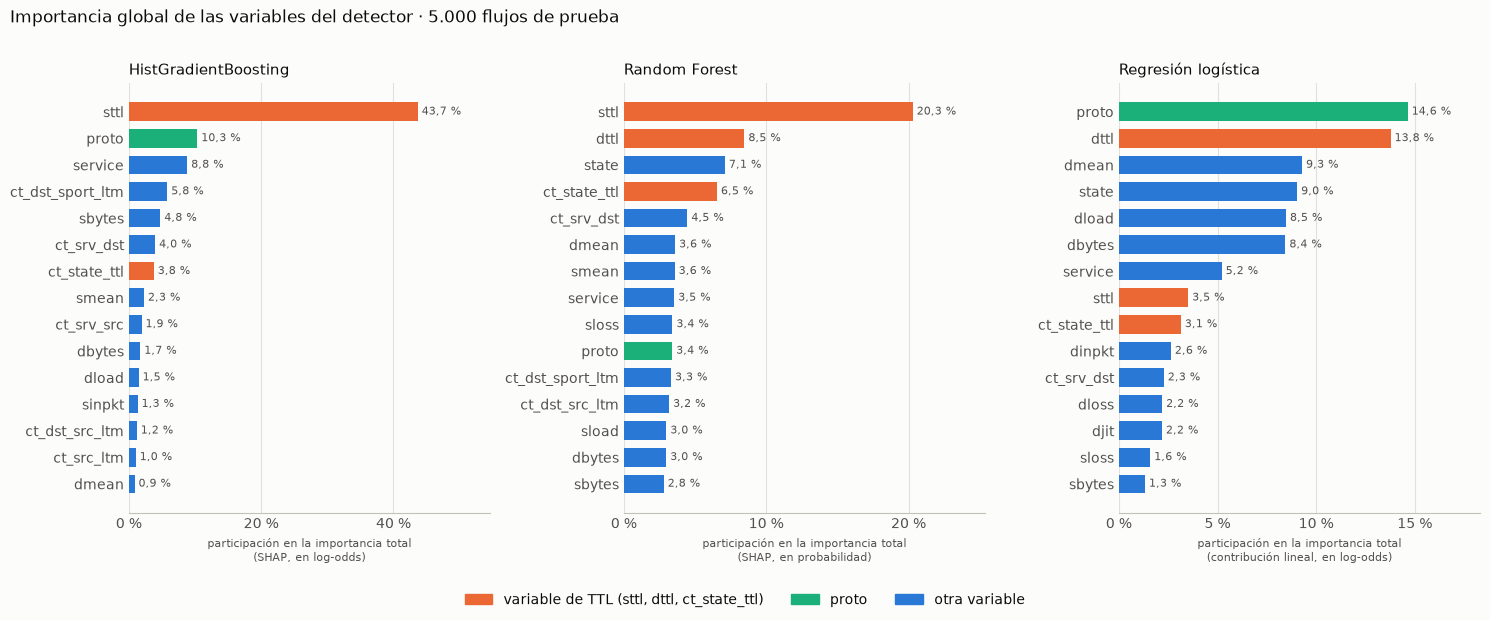

In [27]:
TOP_IMPORTANCE = 15
BAR_COLORS = {"ttl": "#eb6834", "proto": "#1baf7a", "other": "#2a78d6"}
BAR_LABELS = {"ttl": "variable de TTL (sttl, dttl, ct_state_ttl)", "proto": "proto", "other": "otra variable"}
TITLES = {"hist_gradient_boosting": "HistGradientBoosting", "random_forest": "Random Forest", "logistic_regression": "Regresión logística"}
METHODS = {"hist_gradient_boosting": "SHAP", "random_forest": "SHAP", "logistic_regression": "contribución lineal"}
kind_of = lambda feature: "ttl" if feature in TTL_VARIABLES else ("proto" if feature == "proto" else "other")

fig, axes = plt.subplots(1, len(IMPORTANCE_MODELS), figsize=(15, 6.2), facecolor=SURFACE)
for ax, (name, scale) in zip(axes, IMPORTANCE_MODELS.items()):
    rows = first_sample[first_sample["model"] == name].head(TOP_IMPORTANCE).iloc[::-1]
    ax.set_facecolor(SURFACE)
    ax.barh(range(len(rows)), rows["share"], height=0.7, color=[BAR_COLORS[kind_of(f)] for f in rows["feature"]])
    for position, share in enumerate(rows["share"]):
        ax.text(share, position, f" {share * 100:.1f} %".replace(".", ","), va="center", color=MUTED, fontsize=8)
    ax.set_yticks(range(len(rows)), rows["feature"], color=INK)
    ax.xaxis.set_major_formatter(percent)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    ax.set_xlim(0, rows["share"].max() * 1.25)
    ax.set_xlabel(f"participación en la importancia total\n({METHODS[name]}, en {scale})", color=MUTED, fontsize=8)
    ax.set_title(TITLES[name], loc="left", color=INK, fontsize=11)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=BAR_COLORS[k]) for k in BAR_COLORS]
fig.legend(handles, BAR_LABELS.values(), loc="lower center", ncol=3, frameon=False, labelcolor=INK)
fig.suptitle(f"Importancia global de las variables del detector · {IMPORTANCE_SAMPLE_SIZE:,} flujos de prueba".replace(",", "."),
             x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0.06, 1, 0.97))
fig.savefig(MODEL_SEARCH_DIR / "global_importance.png", dpi=200, facecolor=SURFACE)
plt.show()

### Qué muestra la importancia

- **HistGradientBoosting:** `sttl` es la primera variable, con el 43,7 % de la importancia total; le siguen `proto` (10,3 %) y `service` (8,8 %). `ct_state_ttl` está en el lugar 7 (3,8 %). `dttl` queda en el último lugar: su contribución es exactamente 0 en todos los flujos de las dos muestras. Las tres de TTL suman el 47,4 %.
- **Random Forest:** las de TTL ocupan los lugares 1 (`sttl`, 20,3 %), 2 (`dttl`, 8,5 %) y 4 (`ct_state_ttl`, 6,5 %), y suman el 35,3 %; `proto` está en el lugar 10 (3,4 %).
- **Regresión logística:** `proto` es la primera (14,6 %) y `dttl` la segunda (13,8 %); `sttl` está en el lugar 8 (3,5 %) y `ct_state_ttl` en el 9 (3,1 %). Las tres de TTL suman el 20,4 %. Entre los 53 coeficientes, el mayor en valor absoluto es el de `proto_tcp` (−10,99); `dttl` está en el lugar 4 (6,22), `sttl` en el 18 y `ct_state_ttl` en el 19 (1,62 y 1,61).
- **Estabilidad:** con la segunda muestra, la correlación de Spearman es 0,9989 en HistGradientBoosting y 0,9994 en Random Forest y en la regresión logística, y las 10 primeras variables son las mismas y en el mismo orden en los tres modelos. Los lugares de `sttl`, `dttl`, `ct_state_ttl` y `proto` no cambian.

Los tres detectores se apoyan en variables de TTL, en especial los dos de árboles, que es el atajo conocido del dataset. Cuánto cambia la detección sin ellas lo mide la comparación con las versiones M3 de la sección 4.

## 8. Figuras de resultados

Dos figuras de los resultados de prueba para el artículo. No calculan métricas nuevas para comparar modelos: los valores que muestran salen de `test_results.csv`.

- `test_confusion_hgb.png`: las matrices de confusión de HistGradientBoosting, el modelo por defecto, en prueba.
- `test_pr_curves.png`: las curvas precisión-recall en prueba de los 4 modelos registrados en la app.

### Matrices de confusión de HistGradientBoosting en prueba

Salen solo de `test_results.csv`, sin predecir nada:

- **2×2 (detector):** los conteos `tp`, `fp`, `tn` y `fn` guardados. Cada celda trae también el porcentaje de su clase real, así que se leen ahí el recall (ataques con alerta) y la tasa de falsas alarmas (normales con alerta).
- **9×9 (tipo de ataque):** la matriz guardada (`test_type_confusion`). Como en el contrato, se mide solo sobre los ataques reales que dieron alerta. El color es el porcentaje de la fila, es decir, qué parte de los ataques de ese tipo se clasificó como cada tipo; la diagonal es el recall de cada tipo. Cada celda trae el conteo. Como comprobación, la diagonal debe coincidir con el recall de `test_per_type.csv`.

In [28]:
from matplotlib.colors import LinearSegmentedColormap

hgb_row = results.set_index("name").loc["hist_gradient_boosting"]
type_confusion = json.loads(hgb_row["test_metrics_json"])["attack_type"]["confusion"]
type_matrix = pd.DataFrame(type_confusion["matrix"], index=type_confusion["labels"], columns=type_confusion["labels"])
assert type_matrix.values.tolist() == json.loads(hgb_row["test_type_confusion"])
assert type_matrix.values.sum() == hgb_row["test_type_evaluated_flows"] == hgb_row["test_tp"]
type_share = type_matrix.div(type_matrix.sum(axis=1), axis=0)

# Comprobación: la diagonal es el recall de cada tipo guardado en test_per_type.csv.
hgb_test_types = per_type[(per_type["name"] == "hist_gradient_boosting") & (per_type["split"] == "test")]
saved_recall = hgb_test_types.set_index("attack_cat")["recall"]
for attack in type_matrix.index:
    assert abs(type_share.loc[attack, attack] - saved_recall[attack]) < 1e-12, attack
print("Comprobación: la diagonal de la matriz 9×9 coincide con el recall de test_per_type.csv.")

detection_matrix = pd.DataFrame(
    [[hgb_row["test_tp"], hgb_row["test_fn"]], [hgb_row["test_fp"], hgb_row["test_tn"]]],
    index=["ataque real", "normal real"], columns=["alerta", "sin alerta"],
)
display(detection_matrix)
display((type_share * 100).round(1))

Comprobación: la diagonal de la matriz 9×9 coincide con el recall de test_per_type.csv.


,alerta,sin alerta
ataque real,43747,1585
normal real,6116,30884


,Generic,Exploits,Fuzzers,DoS,Reconnaissance,Analysis,Backdoor,Shellcode,Worms
Generic,97.2,1.8,0.1,0.5,0.0,0.1,0.2,0.1,0.0
Exploits,0.2,63.7,1.3,5.5,2.7,4.9,20.5,1.2,0.0
Fuzzers,0.1,5.2,60.9,3.8,0.4,7.8,15.3,6.5,0.0
DoS,0.2,14.0,1.7,19.2,0.9,9.0,53.9,1.1,0.0
Reconnaissance,0.0,5.5,0.6,1.3,83.0,0.7,7.7,1.2,0.0
Analysis,0.0,1.4,0.0,13.6,0.2,29.5,55.3,0.0,0.0
Backdoor,0.0,1.7,0.2,13.3,0.2,31.5,51.8,1.4,0.0
Shellcode,0.5,5.2,6.6,2.2,0.3,0.0,0.3,85.0,0.0
Worms,2.3,22.7,4.5,0.0,0.0,0.0,0.0,0.0,70.5


La figura. Escala de un solo tono (azul), de claro (0 %) a oscuro (100 %); el texto es blanco sobre las celdas oscuras.

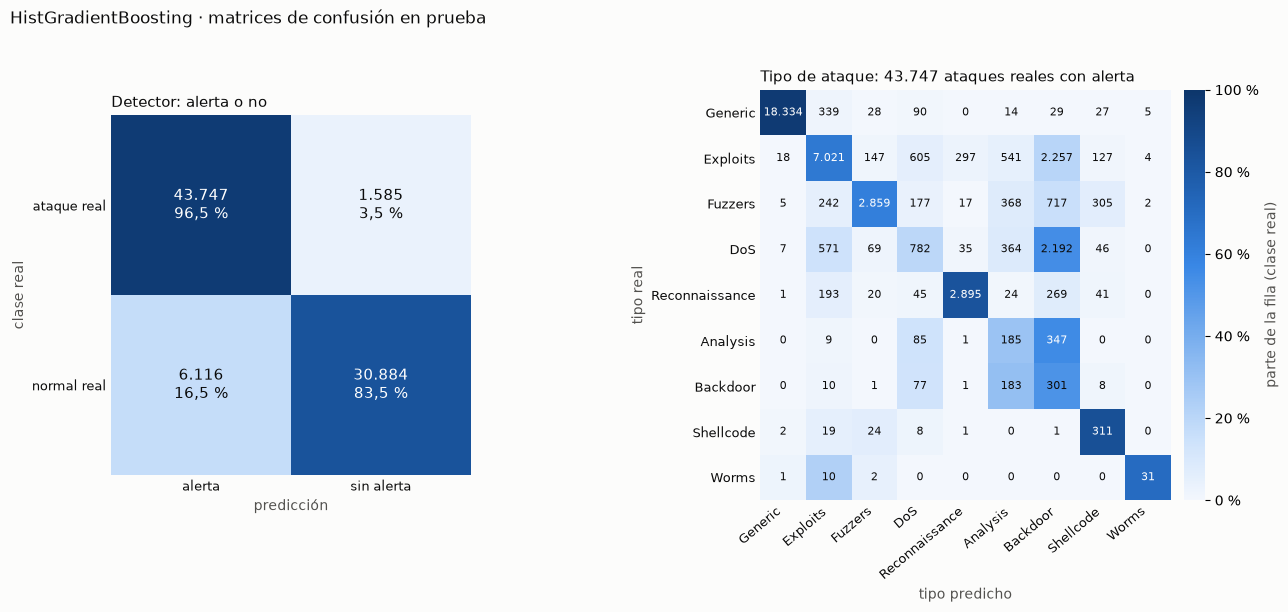

In [29]:
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "azul", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
DARK_CELL = 0.55  # desde esta fracción, el texto de la celda va en blanco


def matrix_panel(ax, shares, counts, title, xlabel, ylabel, fontsize):
    ax.imshow(shares.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1)
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            share, count = shares.iat[i, j], counts.iat[i, j]
            # En la 2×2 van el conteo y el porcentaje de la fila; en la 9×9, solo el conteo (el color es el porcentaje).
            text = thousands(count) + (f"\n{share * 100:.1f} %".replace(".", ",") if fontsize > 8 else "")
            ax.text(j, i, text, ha="center", va="center", fontsize=fontsize,
                    color="white" if share >= DARK_CELL else INK)
    ax.set_xticks(range(shares.shape[1]), shares.columns, rotation=40 if shares.shape[1] > 2 else 0,
                  ha="right" if shares.shape[1] > 2 else "center", color=INK, fontsize=9)
    ax.set_yticks(range(shares.shape[0]), shares.index, color=INK, fontsize=9)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)


detection_share = detection_matrix.div(detection_matrix.sum(axis=1), axis=0)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.9]}, facecolor=SURFACE)
matrix_panel(left, detection_share, detection_matrix, "Detector: alerta o no", "predicción", "clase real", 11)
matrix_panel(right, type_share, type_matrix,
             f"Tipo de ataque: {thousands(type_matrix.values.sum())} ataques reales con alerta", "tipo predicho", "tipo real", 8)
colorbar = fig.colorbar(plt.cm.ScalarMappable(cmap=SEQUENTIAL, norm=plt.Normalize(0, 1)), ax=right, fraction=0.035, pad=0.02)
colorbar.ax.yaxis.set_major_formatter(percent)
colorbar.set_label("parte de la fila (clase real)", color=MUTED)
colorbar.outline.set_visible(False)
fig.suptitle("HistGradientBoosting · matrices de confusión en prueba", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(MODEL_SEARCH_DIR / "test_confusion_hgb.png", dpi=200, facecolor=SURFACE)
plt.show()

Lo que muestran las matrices:

- **Detector:** de los 45.332 ataques reales de la prueba, 43.747 dieron alerta (96,5 %) y 1.585 no (3,5 %); de los 37.000 normales, 6.116 dieron falsa alarma (16,5 %).
- **Tipo de ataque, recall de cada tipo (la diagonal):** Generic 97,2 %, Shellcode 85,0 %, Reconnaissance 83,0 %, Worms 70,5 % (31 de 44, pocos flujos), Exploits 63,7 %, Fuzzers 60,9 %, Backdoor 51,8 %, Analysis 29,5 % y DoS 19,2 %.
- **La mayor confusión va hacia Backdoor:** se clasificaron como Backdoor el 53,9 % de los DoS, el 55,3 % de los Analysis, el 20,5 % de los Exploits y el 15,3 % de los Fuzzers. Entre Analysis y Backdoor la confusión va en los dos sentidos (el 31,5 % de los Backdoor salió como Analysis).

### Curvas precisión-recall en prueba

- **Cómo se calculan.** Los 4 modelos registrados se cargan de `artifacts/models/` y predicen la prueba con `predict_flows`, como en la evaluación: son las mismas predicciones, sin entrenar nada y sin cambiar `test_results.csv`. La curva sale de `precision_recall_curve` de scikit-learn.
- **Valores que se muestran.** La PR-AUC de la leyenda es la guardada en `test_results.csv`, no una calculada de nuevo. El punto de cada curva es el punto de operación del modelo con su umbral: el recall y la precisión guardados. La línea punteada es la precisión de un clasificador al azar, igual a la proporción de ataques en la prueba.
- **Comprobación.** La PR-AUC de cada curva (precisión promedio, `average_precision_score`) debe coincidir con la guardada con una tolerancia de 1e-6. No es 0 por Random Forest: con `n_jobs=-1` suma sus árboles en paralelo y en distinto orden, y sus probabilidades cambian hasta unos 2·10⁻¹⁶ de una predicción a otra. Además, sus probabilidades son promedios de las hojas de 50 árboles, así que muchos flujos comparten exactamente la misma; la PR-AUC trata cada empate como un solo punto de la curva, y ese ruido rompe los empates de forma distinta en cada predicción. En 20 predicciones de la prueba, la PR-AUC de Random Forest difirió de la guardada entre 1,7·10⁻¹¹ y 7,7·10⁻¹⁰ (mediana 1,5·10⁻¹⁰). La tolerancia de 1e-6 deja un margen de unas 1.300 veces sobre ese máximo y sigue siendo 500 veces menor que un cambio en el tercer decimal con que se reporta (±0,0005). Los otros 3 modelos dan siempre la misma probabilidad.
- **Figura.** A la izquierda, las curvas completas; a la derecha, un acercamiento con recall de 0,90 a 1,00 y precisión de 0,70 a 1,00, donde están los puntos de operación y donde se separan las curvas. Cada modelo tiene su color, su tipo de línea y su marcador.

In [30]:
from sklearn.metrics import average_precision_score, precision_recall_curve

PR_AUC_TOLERANCE = 1e-6  # ruido de Random Forest con n_jobs=-1 y empates de probabilidad (ver el texto de arriba)
PR_STYLES = {
    "hist_gradient_boosting": ("HistGradientBoosting", "#2a78d6", "-", "o"),
    "random_forest": ("Random Forest", "#eb6834", "--", "s"),
    "mlp": ("Red neuronal (MLP)", "#1baf7a", "-.", "^"),
    "logistic_regression": ("Regresión logística (modelo base)", "#eda100", ":", "D"),
}

test_flows = parts["test"]
y_test = test_flows["label"].to_numpy()
saved = results.set_index("name")
curves = {}
for name in PR_STYLES:
    info = read_model_info(name)
    probability, _, _ = predict_flows(load_model(name, info), info, test_flows)
    difference = abs(average_precision_score(y_test, probability) - saved.loc[name, "test_pr_auc"])
    assert difference <= PR_AUC_TOLERANCE, f"{name}: la PR-AUC difiere {difference:.1e} de la guardada"
    precision, recall, _ = precision_recall_curve(y_test, probability)
    curves[name] = (recall, precision)
    print(f"{name}: PR-AUC guardada {saved.loc[name, 'test_pr_auc']:.3f} · diferencia con la curva {difference:.1e}")
attack_share = y_test.mean()
print(f"Proporción de ataques en prueba: {int(y_test.sum()):,} de {len(y_test):,} ({attack_share:.1%})".replace(",", "."))

hist_gradient_boosting: PR-AUC guardada 0.988 · diferencia con la curva 0.0e+00
random_forest: PR-AUC guardada 0.989 · diferencia con la curva 1.1e-09
mlp: PR-AUC guardada 0.984 · diferencia con la curva 1.1e-16
logistic_regression: PR-AUC guardada 0.972 · diferencia con la curva 0.0e+00
Proporción de ataques en prueba: 45.332 de 82.332 (55.1%)


La figura `test_pr_curves.png`.

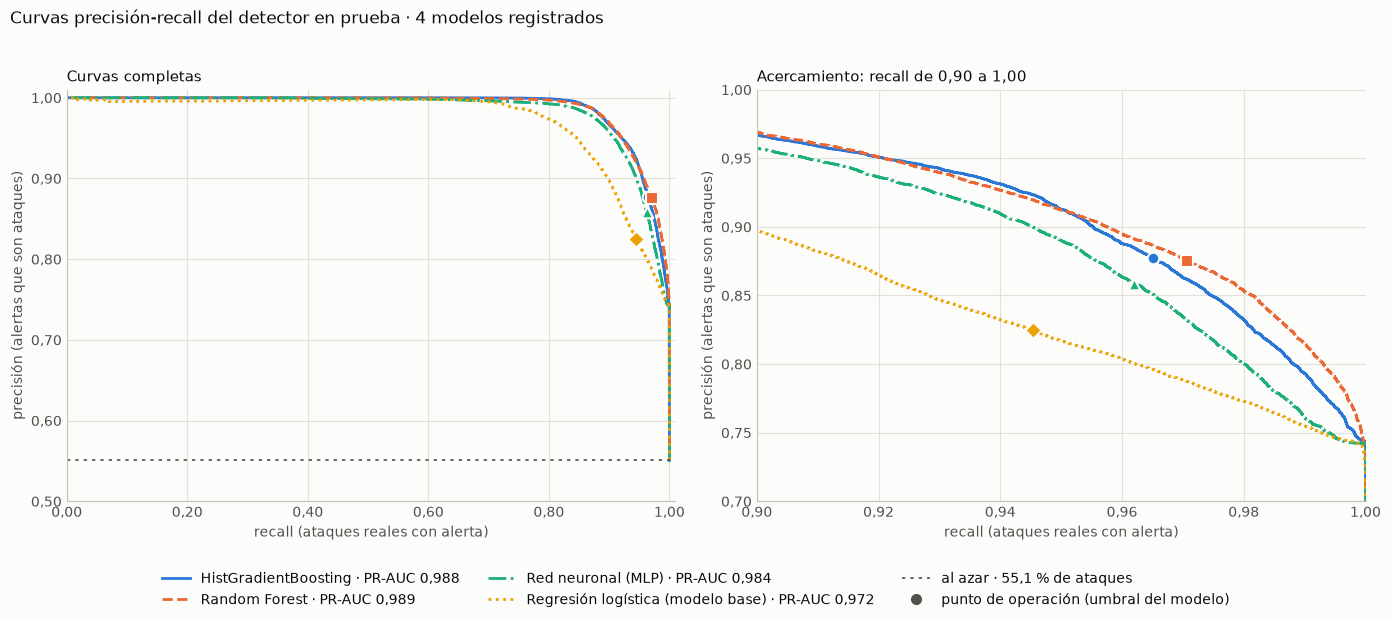

In [31]:
ZOOM = {"recall": (0.90, 1.00), "precision": (0.70, 1.00)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), facecolor=SURFACE)
for ax, zoomed in zip(axes, (False, True)):
    ax.set_facecolor(SURFACE)
    for name, (label, color, line, marker) in PR_STYLES.items():
        recall, precision = curves[name]
        ax.plot(recall, precision, color=color, linestyle=line, linewidth=2,
                label=f"{label} · PR-AUC {saved.loc[name, 'test_pr_auc']:.3f}".replace(".", ","))
        ax.scatter(saved.loc[name, "test_recall"], saved.loc[name, "test_precision"], s=70, marker=marker,
                   color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.axhline(attack_share, color=MUTED, linestyle=(0, (2, 3)), linewidth=1.2,
               label=f"al azar · {attack_share * 100:.1f} % de ataques".replace(".", ","))
    if zoomed:
        ax.set_xlim(*ZOOM["recall"])
        ax.set_ylim(*ZOOM["precision"])
        ax.set_title("Acercamiento: recall de 0,90 a 1,00", loc="left", color=INK, fontsize=11)
    else:
        ax.set_xlim(0, 1.01)
        ax.set_ylim(0.5, 1.01)
        ax.set_title("Curvas completas", loc="left", color=INK, fontsize=11)
    ax.xaxis.set_major_formatter(decimal)
    ax.yaxis.set_major_formatter(decimal)
    ax.set_xlabel("recall (ataques reales con alerta)", color=MUTED)
    ax.set_ylabel("precisión (alertas que son ataques)", color=MUTED)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
handles, labels = axes[0].get_legend_handles_labels()
point = plt.Line2D([], [], color=MUTED, marker="o", linestyle="none", markersize=7, label="punto de operación (umbral del modelo)")
fig.legend([*handles, point], [*labels, point.get_label()], loc="lower center", ncol=3, frameon=False, labelcolor=INK)
fig.suptitle("Curvas precisión-recall del detector en prueba · 4 modelos registrados", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout(rect=(0, 0.1, 1, 0.96))
fig.savefig(MODEL_SEARCH_DIR / "test_pr_curves.png", dpi=200, facecolor=SURFACE)
plt.show()

Lo que muestran las curvas (los valores son los de `test_results.csv`):

- **HistGradientBoosting y Random Forest casi se superponen** en todo el rango (PR-AUC 0,988 y 0,989). En el acercamiento, Random Forest queda por encima en la zona de recall más alto, desde un recall de 0,95 aproximadamente.
- **La red neuronal (0,984)** queda por debajo de los dos en todo el acercamiento, y **la regresión logística (0,972)** por debajo de las demás en casi todo él; las cuatro curvas se juntan cerca de recall 1.
- **Puntos de operación** (umbral de cada modelo): HistGradientBoosting con recall 0,965 y precisión 0,877; Random Forest, 0,971 y 0,875; la red neuronal, 0,962 y 0,859; la regresión logística, 0,945 y 0,825. Todos los umbrales salieron de validación (95 % de los ataques de validación), así que en prueba el recall queda un poco arriba o abajo de 0,95.

## 9. Resumen en `final_results.json`

Un resumen de los resultados finales para el artículo, en un solo archivo JSON. Lo arma `final_results` solo con `test_results.csv` y `registry.json`: no entrena, no predice y no recalcula ninguna métrica.

- **`models`:** los 4 modelos registrados en la app, en el orden de `registry.json`: su método de preprocesamiento, los hiperparámetros y las iteraciones del detector y del clasificador, el umbral, las métricas de validación y de prueba (recall, falsas alarmas, precisión, F1, exactitud, PR-AUC, ROC-AUC, F1 macro de tipos y la matriz de confusión del detector), el tamaño y los tiempos. El modelo base (la regresión logística) va marcado en `kind` y en `base_model`.
- **`reference_models`:** las otras 4 familias y las 3 versiones M3, con las métricas principales en validación y en prueba (recall, falsas alarmas, precisión, F1, PR-AUC y F1 macro). El detalle completo sigue en `test_results.csv`.
- **Una sola vez, arriba:** el modelo por defecto, los flujos de cada parte (entrenamiento, validación y prueba), el equipo y las versiones de scikit-learn y de la búsqueda. `final_results` comprueba que sean iguales en los 4 modelos registrados.
- Los valores van tal como están en `test_results.csv`, sin redondear; los vacíos, como `null`. La tabla se lee con `float_precision="round_trip"`: el conversor rápido que pandas usa por defecto puede cambiar el último dígito de un decimal (por ejemplo, el umbral de Random Forest se leería 0,4894228954095327 en vez de 0,48942289540953277).

Como comprobación, el umbral, el método y las métricas de prueba de cada modelo registrado deben ser los de su `model.json`.

In [32]:
from threat_detector.config import FINAL_RESULTS_JSON
from threat_detector.ml.training import final_results

# round_trip: así los decimales se leen exactos; el conversor rápido de pandas puede cambiar el último dígito.
exact_results = pd.read_csv(TEST_RESULTS_CSV, float_precision="round_trip")
summary = final_results(exact_results, read_registry())
for model in summary["models"]:
    info = read_model_info(model["name"])
    detection = info["test_metrics"]["detection"]
    assert model["threshold"] == info["threshold"] and model["preprocessing_method"] == info["preprocessing_method"]
    assert model["test"]["confusion"] == detection["confusion"]
    assert model["test"]["recall"] == detection["detection_rate"] and model["test"]["pr_auc"] == detection["pr_auc"]
    assert model["test"]["macro_f1"] == info["test_metrics"]["attack_type"]["macro_f1"]
print("Comprobación: el umbral, el método y las métricas de prueba coinciden con el model.json de los 4 modelos.")

FINAL_RESULTS_JSON.write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
print(f"Guardado: artifacts/{MODEL_SEARCH_DIR.name}/{FINAL_RESULTS_JSON.name} "
      f"({len(summary['models'])} modelos registrados y {len(summary['reference_models'])} de referencia)")
print(json.dumps({key: summary[key] for key in ("default_model", "base_model", "data", "environment")}, indent=2, ensure_ascii=False))
display(pd.DataFrame([
    {"name": m["name"], "kind": m["kind"], "method": m["preprocessing_method"], "threshold": m["threshold"],
     "test_recall": m["test"]["recall"], "test_false_alarm_rate": m["test"]["false_alarm_rate"],
     "test_pr_auc": m["test"]["pr_auc"], "test_macro_f1": m["test"]["macro_f1"], "model_size_mb": m["model_size_mb"]}
    for m in summary["models"]
]).style.format({"threshold": "{:.3f}", "test_recall": "{:.1%}", "test_false_alarm_rate": "{:.1%}",
                 "test_pr_auc": "{:.3f}", "test_macro_f1": "{:.3f}", "model_size_mb": "{:.2f}"}).hide(axis="index"))

Comprobación: el umbral, el método y las métricas de prueba coinciden con el model.json de los 4 modelos.
Guardado: artifacts/model_search/final_results.json (4 modelos registrados y 7 de referencia)
{
  "default_model": "hist_gradient_boosting",
  "base_model": "logistic_regression",
  "data": {
    "training_flows": 140273,
    "validation_flows": 35068,
    "test_flows": 82332
  },
  "environment": {
    "hardware": "11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz, 16 núcleos lógicos",
    "sklearn_version": "1.9.1",
    "search_version": 3
  }
}


name,kind,method,threshold,test_recall,test_false_alarm_rate,test_pr_auc,test_macro_f1,model_size_mb
hist_gradient_boosting,elegido,m1,0.689,96.5%,16.5%,0.988,0.560,14.21
random_forest,elegido,m2,0.489,97.1%,16.9%,0.989,0.540,43.41
mlp,elegido,m2,0.432,96.2%,19.4%,0.984,0.462,0.39
logistic_regression,modelo base,m2,0.644,94.5%,24.6%,0.972,0.366,0.03


## 10. Cierre

Los resultados de prueba se reportan en el artículo tal como salen. Ninguna decisión de `CLAUDE.md` cambia por ellos, aunque alguna familia salga mejor en prueba que la elegida.

Materiales para el artículo que salen de este notebook, todos en `artifacts/model_search/` (su origen y cómo se regeneran están en su `README.md`):

- **Resultados (sección 4):** `test_results.csv`, `test_per_type.csv`, `validation_vs_test.png`, `ttl_test.png`, `test_f1_per_type.png`, `oob_vs_validation.csv` y `oob_per_type.csv`.
- **Falsas alarmas (secciones 5 y 6):** `false_alarms_by_category.csv` y su figura, `normal_mix_by_category.png`, `numeric_differences_normals.csv` y sus figuras, y `ttl_254_check.csv`.
- **Importancia global de las variables (sección 7):** `global_importance.csv`, `logistic_coefficients.csv` y `global_importance.png`.
- **Figuras de resultados (sección 8):** `test_confusion_hgb.png` y `test_pr_curves.png`.
- **Resumen (sección 9):** `final_results.json`.

En la etapa de modelos no se hizo selección de variables ni reducción de dimensionalidad; las razones están en el `README.md` de `artifacts/model_search/`.